# Two-group ROI analysis: learners (non-Mandarin) vs. native listeners (Mandarin)

Reads the per-ROI tables written by `extract_roi_values.py` (both groups, all contrasts, one first-level model: `scrubbed-splitfb`) and runs the analyses in `09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md` (R2–R4). The statistics live in `group_stats.py`; this notebook is the sequence of calls plus figures.

**Before trusting anything here:** the learners' rows must reproduce `group_level_all_ROI.ipynb` (section 1b below).

Contrasts:
- `sound`: vs. baseline, both groups (`resp` is in the model as a nuisance regressor but not reported: it follows the sound by <1 s, too close to separate at TR = 3 s)
- `fbcorrect`: correct feedback vs. baseline, both groups -- the feedback contrast for group comparisons
- `fbcorrectvswrong`: learners only (natives get ~1 wrong-feedback trial per run, so it's missing or unreliable for them)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import group_stats as gs

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

nilearn_dir = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn'
group_dir = os.path.join(nilearn_dir, 'group_space-T1w_fwhm-0.00')
roi_dir = os.path.join(group_dir, 'roi-values_scrubbed-splitfb')
out_dir = os.path.join(group_dir, 'stats_two-group')
os.makedirs(out_dir, exist_ok=True)

# resampling settings, matching robustness_checks.py
n_perms, n_boot, seed = 10000, 10000, 0

## 1. Load and check

In [2]:
df = gs.load_roi_values(roi_dir)
print(df.groupby('participant_group').participant_id.nunique())
gs.coverage(df)

participant_group
Mandarin        13
non-Mandarin    12
Name: participant_id, dtype: int64


learning_stage                      early  middle  final
contrast         participant_group                      
fbcorrect        Mandarin              13      13     13
                 non-Mandarin          12      12     12
fbcorrectvswrong Mandarin               6       3      1
                 non-Mandarin          12      12     12
sound            Mandarin              13      13     13
                 non-Mandarin          12      12     12

Inputs `extract_roi_values.py` couldn't find. Expected: Mandarin participants' `fbcorrectvswrong` in stages where a run had no wrong trials. Anything else needs a look.

In [3]:
missing_fpath = os.path.join(roi_dir, 'roi-values_missing.tsv')
try:
    missing = pd.read_csv(missing_fpath, sep='\t')
except pd.errors.EmptyDataError:   # nothing was missing
    missing = pd.DataFrame()
missing

,participant_id,kind,stage,contrast,path
0,sub-FLT03,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
1,sub-FLT03,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
2,sub-FLT03,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
3,sub-FLT05,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
4,sub-FLT05,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
5,sub-FLT08,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
6,sub-FLT08,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
7,sub-FLT08,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
8,sub-FLT10,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
9,sub-FLT10,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...


### 1b. Learners' rows match `group_level_all_ROI.ipynb`'s tables

`group_level_all_ROI.ipynb` now reads its ROI values from the same `extract_roi_values.py` tables, so this is only a consistency check (max difference should be exactly 0). It was the real cross-check while that notebook still masked the maps itself: the two methods agreed exactly on 2026-11-04 (REVISION_PLAN #32). IFGo/IFGt are dropped here, so the PFC row counts are lower.

In [4]:
checks = []
for network in gs.NETWORKS:
    for contrast in ['sound', 'fbcorrectvswrong']:
        nb_fpath = os.path.join(group_dir, f'univariate-results_network-{network}_contrast-{contrast}.tsv')
        if not os.path.exists(nb_fpath):
            continue
        nb_df = pd.read_csv(nb_fpath, sep='\t')
        mine = df[(df.network == network) & (df.contrast == contrast) & (df.participant_group == 'non-Mandarin')]
        merged = mine.merge(nb_df, on=['participant_id', 'region_hemi', 'learning_stage'], suffixes=('', '_nb'))
        checks.append({'network': network, 'contrast': contrast, 'rows_matched': len(merged),
                       'rows_here': len(mine), 'max_abs_diff': (merged.beta - merged.beta_nb).abs().max()})
pd.DataFrame(checks)

,network,contrast,rows_matched,rows_here,max_abs_diff
0,tian-S2,sound,432,432,4.440892e-16
1,tian-S2,fbcorrectvswrong,432,432,0.000000e+00
2,auditory,sound,504,504,4.440892e-16
3,auditory,fbcorrectvswrong,504,504,0.000000e+00
4,pfc,sound,648,648,4.440892e-16
5,pfc,fbcorrectvswrong,648,648,4.440892e-16


## 2. Responses vs. baseline within each group

Stages averaged, hemispheres averaged; FDR across regions within each group × contrast × network.

In [5]:
baseline = gs.baseline_tests(df)
baseline.to_csv(os.path.join(out_dir, 'baseline_by_group.tsv'), sep='\t', index=False)

(baseline[baseline.contrast.isin(['sound', 'fbcorrect'])]
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''))
 .pivot_table(index=['network', 'region'], columns=['contrast', 'participant_group'], values='result', aggfunc='first'))

contrast           fbcorrect                 sound             
participant_group   Mandarin non-Mandarin Mandarin non-Mandarin
network  region                                                
auditory HG             -2.3       -6.15*    7.12*        6.27*
         PP            -2.56       -4.96*    5.65*        4.65*
         PT            -2.82       -3.33*    10.2*        7.49*
         ParsOp         0.88         0.76    2.78*         2.13
         ParsTri        0.23         1.39    -1.27        -1.57
         STGa           0.63        -0.38    7.18*         5.1*
         STGp          -0.42         -0.3    9.47*        8.21*
pfc      ACC           -0.48        -0.02     -0.5        -0.94
         FMC            1.48        -0.84     2.35        -3.1*
         FO            -0.57        -0.17     3.8*        3.84*
         FP            -0.23        -0.09   -2.97*       -6.64*
         MFG           -0.94         0.84    -0.09        -0.21
         OFC           -0.17         0.47    -0.54       -4.39*
         PCG           -0.24         0.64    -0.39         -1.8
         PreCG         -0.16        -1.36    5.85*        6.68*
         SFG             0.4         1.21      0.8        -0.27
tian-S2  NAc-core       0.73         0.18    2.62*        3.93*
         NAc-shell      1.76        -1.97    2.86*         1.28
         aCAU          -0.93          0.2     1.02        3.54*
         aPUT          4.23*        3.23*    7.05*        6.96*
         pCAU           0.23         0.34    -0.02         1.67
         pPUT           1.57         1.52    3.62*         1.83

## 3. Does `fbcorrect` stand in for `fbcorrectvswrong` in learners?

The group comparison of feedback has to use `fbcorrect`. It's only a fair stand-in if, in learners, it shows the same learning-stage trend as the headline `fbcorrectvswrong` effect (plan R3). If it doesn't, section 4's feedback result needs reframing before it's interpreted.

In [6]:
trends = gs.subject_trends(df)
trends.to_csv(os.path.join(out_dir, 'subject_trends.tsv'), sep='\t', index=False)

pd.concat([gs.learner_contrast_agreement(trends, region) for region in ['aCAU', 'aPUT']]).round(3)

,contrast,n,mean_trend,t,p,r,region,group
0,fbcorrectvswrong,12,-0.594,-3.297,0.007,NaN,aCAU,non-Mandarin
1,fbcorrect,12,-0.330,-1.908,0.083,NaN,aCAU,non-Mandarin
2,correlation between the two,12,NaN,NaN,0.445,0.244,aCAU,non-Mandarin
0,fbcorrectvswrong,12,0.017,0.083,0.935,NaN,aPUT,non-Mandarin
1,fbcorrect,12,0.065,0.447,0.664,NaN,aPUT,non-Mandarin
2,correlation between the two,12,NaN,NaN,0.297,0.329,aPUT,non-Mandarin


## 4. Planned test: is the aCAU feedback decline learner-specific?

Per-subject learning-stage trend (`[-1, 0, 1]`, final − early), within each group and learners − natives: Welch t, group-label permutation, leave-one-out, bootstrap CI. Then the same for the aCAU − aPUT differential trend.

In [7]:
planned = pd.concat([
    gs.trend_group_difference(trends, 'fbcorrect', 'aCAU', n_perms=n_perms, n_boot=n_boot, seed=seed),
    gs.trend_group_difference(gs.differential_trend(trends, 'fbcorrect', 'aCAU', 'aPUT'),
                              'fbcorrect', 'aCAU-minus-aPUT', n_perms=n_perms, n_boot=n_boot, seed=seed),
], ignore_index=True)
planned.to_csv(os.path.join(out_dir, 'planned_trend_group_tests.tsv'), sep='\t', index=False)
planned.round(4)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,-0.3297,-1.9076,0.0829,0.0840,1/12,-0.6411,0.0112,fbcorrect,aCAU
1,Mandarin trend vs 0,13,0.0729,0.3920,0.7019,0.7283,0/13,-0.2540,0.4483,fbcorrect,aCAU
2,non-Mandarin - Mandarin (Welch),25,-0.4025,-1.5861,0.1264,0.1298,1/25,-0.8652,0.0840,fbcorrect,aCAU
3,non-Mandarin trend vs 0,12,-0.3949,-2.1782,0.0520,0.0542,3/12,-0.7326,-0.0547,fbcorrect,aCAU-minus-aPUT
4,Mandarin trend vs 0,13,0.2700,1.4077,0.1846,0.1877,0/13,-0.0817,0.6354,fbcorrect,aCAU-minus-aPUT
5,non-Mandarin - Mandarin (Welch),25,-0.6649,-2.5192,0.0192,0.0179,25/25,-1.1525,-0.1733,fbcorrect,aCAU-minus-aPUT


## 4b. Secondary test: is the pPUT sound decline learner-specific?

Learners' pPUT sound response falls from early to final (`group_level_all_ROI.ipynb`: t = 3.52, q = .029); natives' doesn't (t = 1.03). Same tests as section 4 on the `sound` trend. Planned after seeing the within-group results, so it's reported as secondary (plan R2).

In [8]:
secondary = gs.trend_group_difference(trends, 'sound', 'pPUT', n_perms=n_perms, n_boot=n_boot, seed=seed)
secondary.to_csv(os.path.join(out_dir, 'secondary_trend_group_tests.tsv'), sep='\t', index=False)
secondary.round(4)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,-1.4096,-3.5155,0.0048,0.0034,12/12,-2.1998,-0.7098,sound,pPUT
1,Mandarin trend vs 0,13,-0.7095,-1.0306,0.3230,0.3208,0/13,-2.0576,0.5297,sound,pPUT
2,non-Mandarin - Mandarin (Welch),25,-0.7001,-0.8788,0.3904,0.4054,0/25,-2.1539,0.8135,sound,pPUT


## 5. Group × stage, every region

Mixed ANOVA per region (stage within, group between), FDR per contrast × effect across all regions. Exploratory beyond the planned test in section 4.

In [9]:
anova = gs.group_by_stage_anova(df, contrasts=['sound', 'fbcorrect'])
anova.to_csv(os.path.join(out_dir, 'group_by_stage_anova.tsv'), sep='\t', index=False)
anova[anova.q < .05].sort_values(['contrast', 'effect', 'q']).round(4)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q
72,pfc,sound,FMC,group,13.0173,1,23,0.0015,0.3614,"{'Mandarin': 13, 'non-Mandarin': 12}",0.0326


## 5b. Group differences per ROI

Learners − natives, Welch t with Cohen's d and a group-label permutation p, FDR across regions within each contrast × network (× stage). Exploratory, like section 5. `fbcorrectvswrong` is left out because natives mostly lack it.

First with stages averaged per participant (ignoring stage), then separately for each stage. Cells show t, with * for q < .05. Positive t means learners > natives.

In [10]:
group_diff = gs.group_difference_tests(df, n_perms=n_perms, seed=seed)
group_diff.to_csv(os.path.join(out_dir, 'group_difference_stage-avg.tsv'), sep='\t', index=False)

(group_diff
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''))
 .pivot_table(index=['network', 'region'], columns='contrast', values='result', aggfunc='first'))

contrast           fbcorrect   sound
network  region                     
auditory HG            -0.15   -1.76
         PP             0.32   -1.11
         PT            -0.82   -0.52
         ParsOp        -0.04    0.52
         ParsTri         0.8   -0.45
         STGa          -0.72   -0.62
         STGp           0.16  -3.12*
pfc      ACC            0.34   -0.44
         FMC           -1.67  -3.67*
         FO             0.36    -0.1
         FP             0.05   -1.93
         MFG            1.21   -0.07
         OFC            0.45   -2.68
         PCG            0.57   -1.19
         PreCG         -0.51    -0.2
         SFG            0.45    -0.8
tian-S2  NAc-core      -0.41    0.61
         NAc-shell     -2.62   -1.11
         aCAU           0.76     1.4
         aPUT           0.28    0.39
         pCAU           0.15    1.04
         pPUT           -0.7   -1.18

In [11]:
group_diff[group_diff.p < .05].sort_values(['contrast', 'p']).round(4)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
33,tian-S2,fbcorrect,NAc-shell,12,13,-0.2173,0.1340,-0.3513,-2.6211,0.0164,-1.0634,-1.9016,-0.2252,0.0114,0.0986
24,pfc,sound,FMC,12,13,-0.3488,0.4007,-0.7495,-3.6723,0.0015,-1.4443,-2.3252,-0.5635,0.0013,0.0131
13,auditory,sound,STGp,12,13,3.1312,5.2272,-2.0960,-3.1246,0.0051,-1.2307,-2.0863,-0.3752,0.0061,0.0359
28,pfc,sound,OFC,12,13,-1.0032,-0.1257,-0.8775,-2.6815,0.0133,-1.0706,-1.9095,-0.2318,0.0093,0.0600


In [12]:
group_diff_stage = gs.group_difference_tests(df, by_stage=True, n_perms=n_perms, seed=seed)
group_diff_stage.to_csv(os.path.join(out_dir, 'group_difference_by-stage.tsv'), sep='\t', index=False)

(group_diff_stage
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''),
         learning_stage=lambda d: pd.Categorical(d.learning_stage, gs.STAGE_ORDER, ordered=True))
 .pivot_table(index=['network', 'region'], columns=['contrast', 'learning_stage'], values='result',
              aggfunc='first', observed=True))

contrast           fbcorrect                sound              
learning_stage         early middle  final  early middle  final
network  region                                                
auditory HG             0.87   0.15  -1.08  -0.16  -1.21  -1.89
         PP             0.54  -0.22   0.24   0.49  -0.92  -1.32
         PT             1.36  -1.02  -0.99    0.6  -0.43  -0.84
         ParsOp         1.09   1.21  -2.02   0.56   2.26  -1.51
         ParsTri        2.15   1.12  -2.41    0.9   0.17  -1.52
         STGa           2.18  -1.51  -1.29   0.65   0.06  -1.78
         STGp           1.06   -0.3  -0.26  -2.76  -1.61  -2.29
pfc      ACC            0.92   0.08  -0.17  -0.18   -0.8   0.16
         FMC           -0.85  -0.59  -1.23   -2.6  -1.66  -1.39
         FO             1.78   0.33  -0.86   0.98  -0.12  -1.15
         FP             0.92   0.87  -1.59   0.06  -0.37  -2.37
         MFG            1.43    2.7  -1.36   0.32   1.85   -1.8
         OFC            1.34   0.25  -1.03  -0.74  -2.08  -2.18
         PCG             0.9   1.55  -1.14  -0.22  -0.97  -1.12
         PreCG          0.81  -1.57   0.07   0.25  -0.07  -0.57
         SFG            0.93   3.04  -1.76   0.39   -0.4  -2.02
tian-S2  NAc-core      -0.07    0.8  -1.29   0.81   0.87  -0.28
         NAc-shell     -1.54  -1.51  -1.03  -0.97  -0.14  -1.26
         aCAU            1.4   0.62  -0.41   0.83   1.24   1.21
         aPUT          -0.46  -0.04   0.69   0.22   0.23   0.31
         pCAU          -0.15   1.15  -0.78   0.49    2.1  -0.34
         pPUT          -1.34   -1.5   0.93  -0.28  -1.11  -1.34

In [13]:
# sensitivity: FLT15 is Mandarin in participants.tsv but absent from the behavior
# summary (TWO_GROUP_MANUSCRIPT_PLAN.md, Sample) -- do the stage-averaged results hold without them?
group_diff_no15 = gs.group_difference_tests(df[df.participant_id != 'sub-FLT15'], n_perms=0)
(group_diff[['network', 'contrast', 'region', 't', 'q']]
 .merge(group_diff_no15[['network', 'contrast', 'region', 't', 'q']], on=['network', 'contrast', 'region'],
        suffixes=('', '_without_FLT15'))
 .query('q < .05 or q_without_FLT15 < .05').round(4))

,network,contrast,region,t,q,t_without_FLT15,q_without_FLT15
13,auditory,sound,STGp,-3.1246,0.0359,-2.8018,0.0787
24,pfc,sound,FMC,-3.6723,0.0131,-3.4497,0.0254


## 5c. Group × hemisphere

Natives' striatal sound response is left-weighted (`group_level_all_ROI.ipynb`, hemisphere F(1, 12) = 6.87); learners' isn't. Per participant, left − right with stages averaged; within each group vs. 0, and learners − natives (with two hemispheres, the group × hemisphere interaction). `all regions` is the network mean, one planned test per network (its within-group t² reproduces that notebook's hemisphere F); single regions are FDR-corrected within contrast × network.

In [14]:
laterality = gs.laterality_tests(df, n_perms=n_perms, seed=seed)
laterality.to_csv(os.path.join(out_dir, 'group_by_hemisphere.tsv'), sep='\t', index=False)
laterality[laterality.region == 'all regions'].round(4)

,network,contrast,region,n_non-Mandarin,mean_non-Mandarin,t_non-Mandarin,p_non-Mandarin,n_Mandarin,mean_Mandarin,t_Mandarin,p_Mandarin,difference,t,p,d,permutation_p,q
7,auditory,fbcorrect,all regions,12,0.1974,2.5754,0.0258,13,0.0645,0.9229,0.3743,0.1330,1.2823,0.2128,0.5145,0.2061,NaN
15,auditory,sound,all regions,12,0.2415,0.8145,0.4326,13,0.0431,0.2078,0.8389,0.1983,0.5480,0.5897,0.2222,0.5921,NaN
25,pfc,fbcorrect,all regions,12,0.1435,2.3695,0.0372,13,0.1063,1.7432,0.1068,0.0372,0.4333,0.6689,0.1731,0.6637,NaN
35,pfc,sound,all regions,12,0.6207,3.2711,0.0075,13,0.2048,1.5449,0.1483,0.4159,1.7966,0.0875,0.7285,0.0821,NaN
40,tian-S2,fbcorrect,all regions,12,0.1358,1.5997,0.1380,13,0.1629,2.8784,0.0139,-0.0271,-0.2653,0.7936,-0.1078,0.8046,NaN
47,tian-S2,sound,all regions,12,0.1606,0.6482,0.5302,13,0.5733,2.6204,0.0224,-0.4127,-1.2483,0.2248,-0.5015,0.2266,NaN


In [15]:
laterality[(laterality.region != 'all regions') & (laterality.p < .05)].sort_values(['contrast', 'p']).round(4)

,network,contrast,region,n_non-Mandarin,mean_non-Mandarin,t_non-Mandarin,p_non-Mandarin,n_Mandarin,mean_Mandarin,t_Mandarin,p_Mandarin,difference,t,p,d,permutation_p,q
5,auditory,fbcorrect,STGa,12,0.2776,3.3919,0.006,13,-0.0896,-0.8233,0.4264,0.3672,2.6964,0.0132,1.0654,0.013,0.0927


## 5d. Equivalence tests (TOST)

"Present in both groups" and "no change in natives" are claims of *no difference*, which a non-significant p can't support. Two one-sided tests per region: equivalence holds when the 90% CI lies inside ±bound (q_tost < .05, FDR within each claim). Bounds are in beta units and set by the rules in `TWO_GROUP_MANUSCRIPT_PLAN.md` (R2, R3), each tied to a learner effect:

| Claim | Test | Bound |
|---|---|---|
| Striatal sound level is similar in both groups | learners − natives, stage-averaged `sound` | half the striatal mean sound response (all regions, both groups) |
| Natives' striatal feedback response doesn't change | natives' `fbcorrect` trend vs 0 | the learners' headline aCAU `fbcorrectvswrong` trend |
| Natives' striatal sound response doesn't change | natives' `sound` trend vs 0 | the learners' pPUT `sound` trend (their largest sound change) |
| pPUT sound decline is similar in both groups | learners − natives, `sound` trend | the learners' pPUT `sound` trend |

`bound_reached` is the smallest bound equivalence would pass at, whatever the verdict; `BF01` > 3 is moderate evidence for no difference (JZS, default prior). With 12 vs 13 participants, expect equivalence only at large bounds (≈ d 1.2 two-sample, 0.85 one-sample).

In [16]:
striatum = ['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-core', 'NAc-shell']
means = gs.subject_means(df)
striatal_sound = means.query("network == 'tian-S2' and contrast == 'sound'")
learner_trend = lambda contrast, region: trends.query(
    "participant_group == 'non-Mandarin' and contrast == @contrast and region == @region").trend.mean()

# bounds, by the rules above
bound_sound_level = 0.5 * striatal_sound.beta.mean()
bound_fb_trend = abs(learner_trend('fbcorrectvswrong', 'aCAU'))
bound_sound_trend = abs(learner_trend('sound', 'pPUT'))
print(f'bounds: sound level {bound_sound_level:.3f}, feedback trend {bound_fb_trend:.3f}, '
      f'sound trend {bound_sound_trend:.3f}')

striatal_trends = trends[trends.network == 'tian-S2']
equivalence = pd.concat([
    gs.equivalence_tests(striatal_sound, 'beta', dict.fromkeys(striatum, bound_sound_level),
                         'sound level similar in both groups'),
    gs.equivalence_tests(striatal_trends[striatal_trends.contrast == 'fbcorrect'], 'trend',
                         dict.fromkeys(striatum, bound_fb_trend), 'natives: no feedback change',
                         one_group='Mandarin'),
    gs.equivalence_tests(striatal_trends[striatal_trends.contrast == 'sound'], 'trend',
                         dict.fromkeys(striatum, bound_sound_trend), 'natives: no sound change',
                         one_group='Mandarin'),
    gs.equivalence_tests(striatal_trends[striatal_trends.contrast == 'sound'], 'trend',
                         {'pPUT': bound_sound_trend}, 'pPUT sound decline similar in both groups'),
], ignore_index=True)
equivalence.to_csv(os.path.join(out_dir, 'equivalence_tests.tsv'), sep='\t', index=False)
equivalence.round(3)

bounds: sound level 0.660, feedback trend 0.594, sound trend 1.410


,claim,region,test,estimate,bound,df,p_tost,ci90_lower,ci90_upper,bound_reached,BF01,q_tost,equivalent
0,sound level similar in both groups,aCAU,non-Mandarin - Mandarin,1.017,0.660,22.233,0.686,-0.231,2.265,2.265,1.362,0.686,False
1,sound level similar in both groups,pCAU,non-Mandarin - Mandarin,1.084,0.660,22.103,0.656,-0.702,2.869,2.869,1.845,0.686,False
2,sound level similar in both groups,aPUT,non-Mandarin - Mandarin,0.234,0.660,22.587,0.242,-0.796,1.264,1.264,2.568,0.686,False
3,sound level similar in both groups,pPUT,non-Mandarin - Mandarin,-0.696,0.660,22.830,0.524,-1.709,0.317,1.709,1.641,0.686,False
4,sound level similar in both groups,NAc-core,non-Mandarin - Mandarin,0.401,0.660,22.818,0.348,-0.720,1.523,1.523,2.370,0.686,False
5,sound level similar in both groups,NAc-shell,non-Mandarin - Mandarin,-0.563,0.660,22.940,0.425,-1.434,0.308,1.434,1.739,0.686,False
6,natives: no feedback change,aCAU,Mandarin vs 0,0.073,0.594,12.000,0.008,-0.258,0.404,0.404,3.361,0.024,True
7,natives: no feedback change,pCAU,Mandarin vs 0,-0.045,0.594,12.000,0.062,-0.635,0.545,0.635,3.565,0.084,False
8,natives: no feedback change,aPUT,Mandarin vs 0,-0.197,0.594,12.000,0.078,-0.663,0.268,0.663,2.814,0.084,False
9,natives: no feedback change,pPUT,Mandarin vs 0,-0.215,0.594,12.000,0.084,-0.674,0.244,0.674,2.669,0.084,False


## 6. Figure: stage profiles by group

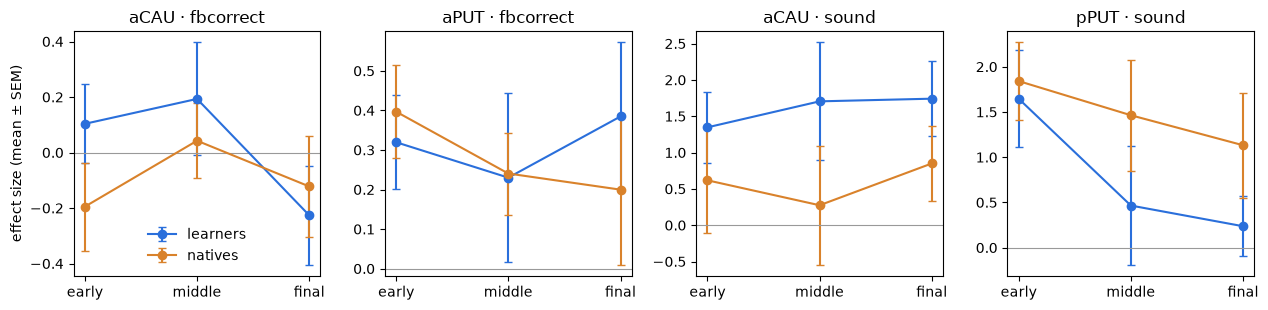

In [17]:
bilat = gs.bilateral_mean(df)
panels = [('fbcorrect', 'aCAU'), ('fbcorrect', 'aPUT'), ('sound', 'aCAU'), ('sound', 'pPUT')]
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}

fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.2), sharey=False)
for ax, (contrast, region) in zip(axes, panels):
    sub = bilat[(bilat.contrast == contrast) & (bilat.region == region)]
    for group in gs.GROUPS:
        g = sub[sub.participant_group == group].groupby('learning_stage').beta
        mean, sem = g.mean().reindex(gs.STAGE_ORDER), g.sem().reindex(gs.STAGE_ORDER)
        ax.errorbar(range(3), mean, yerr=sem, marker='o', capsize=3, color=colors[group],
                    label='learners' if group == 'non-Mandarin' else 'natives')
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_xticks(range(3), gs.STAGE_ORDER)
    ax.set_title(f'{region} · {contrast}')
axes[0].set_ylabel('effect size (mean ± SEM)')
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'stage_profiles_by_group.png'), dpi=300)

## 6b. Group-difference figures

Learners − natives, everywhere: red = learners higher, blue = natives higher.

1. **Forest plot**: every ROI's group difference as Cohen's d with an approximate 95% CI, for stage-averaged responses (section 5b) and for the learning-stage trend (final − early). Filled = q < .05 (FDR within contrast × network).
2. **ROI maps** of the Welch t, same renderers as `group_level_all_ROI.ipynb`, one shared colour scale. Group tests average hemispheres, so each region's bilateral t is painted on both hemispheres; hemisphere differences are section 5c. `*` and a thick outline mark q < .05.
3. **The three key results** as per-participant points.

The trend tests here are per region and exploratory; the planned aCAU and aCAU − aPUT tests are section 4.

In [18]:
import sys
from scipy import stats
sys.path.insert(0, '..')   # plotting modules live at the repo root
from nilearn import datasets
from roi_surface_plotting import plot_roi_surface_stat, build_mask_path_dict
from striatal_roi_plotting import plot_striatal_roi_stat

masks_dir = os.path.join(nilearn_dir, 'masks')
surf_space_label = 'MNI152NLin2009cAsym'   # masks the plotting functions read, as in group_level_all_ROI
fsaverage = datasets.fetch_surf_fsaverage('fsaverage')

fig_dir = os.path.join(os.getcwd(), 'figures', 'two-group')
os.makedirs(fig_dir, exist_ok=True)

# surface maps are 3D meshes: as SVG they run to 100+ MB (over GitHub's file
# limit), so they're saved as PNG only, as in group_level_all_ROI
def save(fig, name, exts=('png', 'svg')):
    for ext in exts:
        fig.savefig(os.path.join(fig_dir, f'{name}.{ext}'), bbox_inches='tight')

# per-region trend differences (exploratory companion to section 4)
trend_diff = gs.trend_difference_tests(trends, n_perms=n_perms, seed=seed)
trend_diff.to_csv(os.path.join(out_dir, 'group_difference_trend.tsv'), sep='\t', index=False)
trend_diff[trend_diff.p < .05].round(4)

[fetch_surf_fsaverage] Dataset directory found: /ihome/bchandrasekaran/krs228/nilearn_data/fsaverage

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
3,auditory,fbcorrect,ParsOp,12,13,-0.2375,0.5720,-0.8095,-2.5109,0.0195,-1.0028,-1.8352,-0.1704,0.0189,0.0456
4,auditory,fbcorrect,ParsTri,12,13,-0.2394,0.7596,-0.9990,-2.9804,0.0068,-1.1801,-2.0302,-0.3300,0.0056,0.0296
5,auditory,fbcorrect,STGa,12,13,-0.1252,0.4661,-0.5913,-2.8802,0.0085,-1.1466,-1.9932,-0.3000,0.0110,0.0296
11,auditory,sound,ParsTri,12,13,-0.3890,1.7077,-2.0967,-2.1184,0.0469,-0.8316,-1.6494,-0.0138,0.0520,0.1473
12,auditory,sound,STGa,12,13,-0.1385,2.6322,-2.7707,-2.6150,0.0168,-1.0254,-1.8600,-0.1909,0.0185,0.1175
18,pfc,fbcorrect,MFG,12,13,-0.0336,0.5034,-0.5370,-2.2438,0.0348,-0.8947,-1.7176,-0.0718,0.0365,0.1817


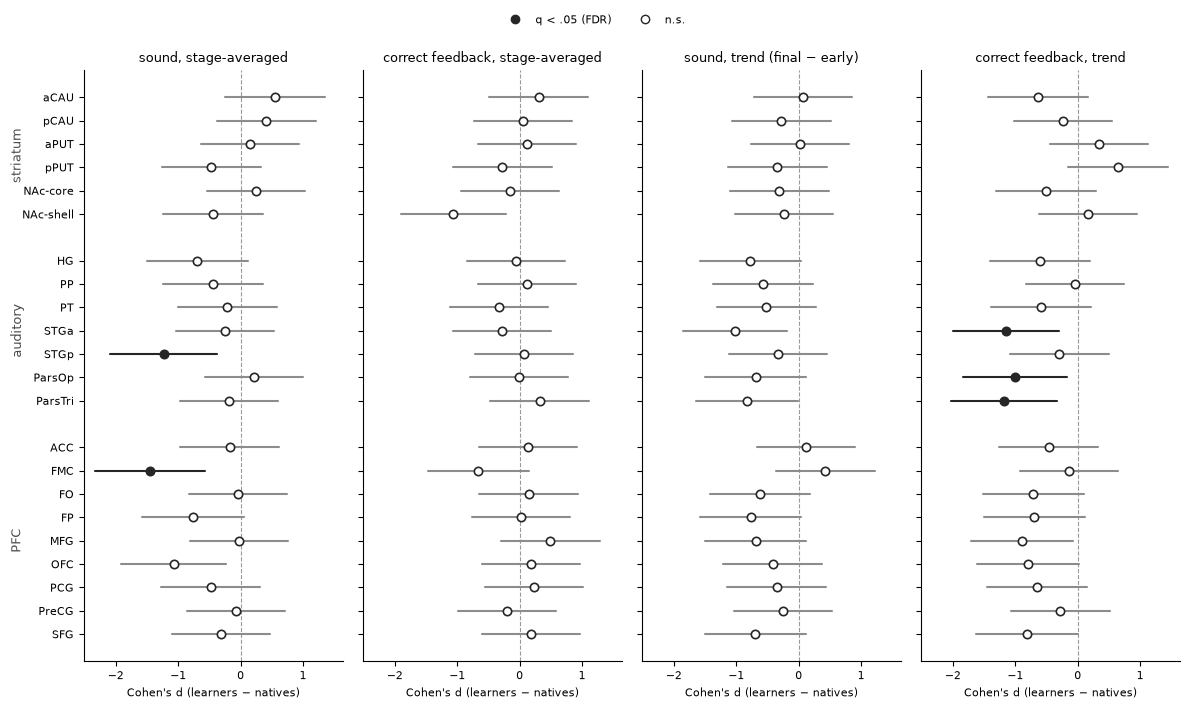

In [19]:
# 1. forest plot: d with 95% CI, every ROI, stage-averaged and trend
REGION_ORDER = {'tian-S2': ['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-core', 'NAc-shell'],
                'auditory': ['HG', 'PP', 'PT', 'STGa', 'STGp', 'ParsOp', 'ParsTri'],
                'pfc': ['ACC', 'FMC', 'FO', 'FP', 'MFG', 'OFC', 'PCG', 'PreCG', 'SFG']}
NETWORK_LABEL = {'tian-S2': 'striatum', 'auditory': 'auditory', 'pfc': 'PFC'}
rows_y = [(net, reg) for net in REGION_ORDER for reg in REGION_ORDER[net]]
y_of = {key: -i - 1.0 * list(REGION_ORDER).index(key[0]) for i, key in enumerate(rows_y)}  # gap between networks

panels = [(group_diff, 'sound', 'sound, stage-averaged'), (group_diff, 'fbcorrect', 'correct feedback, stage-averaged'),
          (trend_diff, 'sound', 'sound, trend (final − early)'), (trend_diff, 'fbcorrect', 'correct feedback, trend')]
fig, axes = plt.subplots(1, len(panels), figsize=(3.0 * len(panels), 0.24 * len(y_of) + 1.5), sharex=True, sharey=True)
for ax, (results, contrast, title) in zip(axes, panels):
    sub = results[results.contrast == contrast].set_index(['network', 'region'])
    for key, y in y_of.items():
        if key not in sub.index:
            continue
        r = sub.loc[key]
        significant = r.q < .05
        ax.plot([r.d_ci_lower, r.d_ci_upper], [y, y], color='0.55' if not significant else '0.15', lw=1.5,
                solid_capstyle='round', zorder=1)
        ax.plot(r.d, y, 'o', ms=6, mfc='0.15' if significant else 'white', mec='0.15', mew=1.2, zorder=2)
    ax.axvline(0, color='0.6', lw=0.8, ls='--', zorder=0)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Cohen's d (learners − natives)", fontsize=8)
    ax.tick_params(labelsize=8)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(list(y_of.values()), [reg for _, reg in y_of])
for net in REGION_ORDER:   # network labels at the left of each block
    ys = [y for (n, _), y in y_of.items() if n == net]
    axes[0].annotate(NETWORK_LABEL[net], xy=(0, np.mean(ys)), xycoords=('axes fraction', 'data'),
                     xytext=(-48, 0), textcoords='offset points', rotation=90, ha='center', va='center',
                     fontsize=9, color='0.3')
axes[-1].plot([], [], 'o', mfc='0.15', mec='0.15', label='q < .05 (FDR)')
axes[-1].plot([], [], 'o', mfc='white', mec='0.15', label='n.s.')
fig.tight_layout()
fig.legend(*axes[-1].get_legend_handles_labels(), fontsize=8, frameon=False, ncol=2,
           loc='lower center', bbox_to_anchor=(.5, 1.0))
save(fig, 'group-diff_forest')

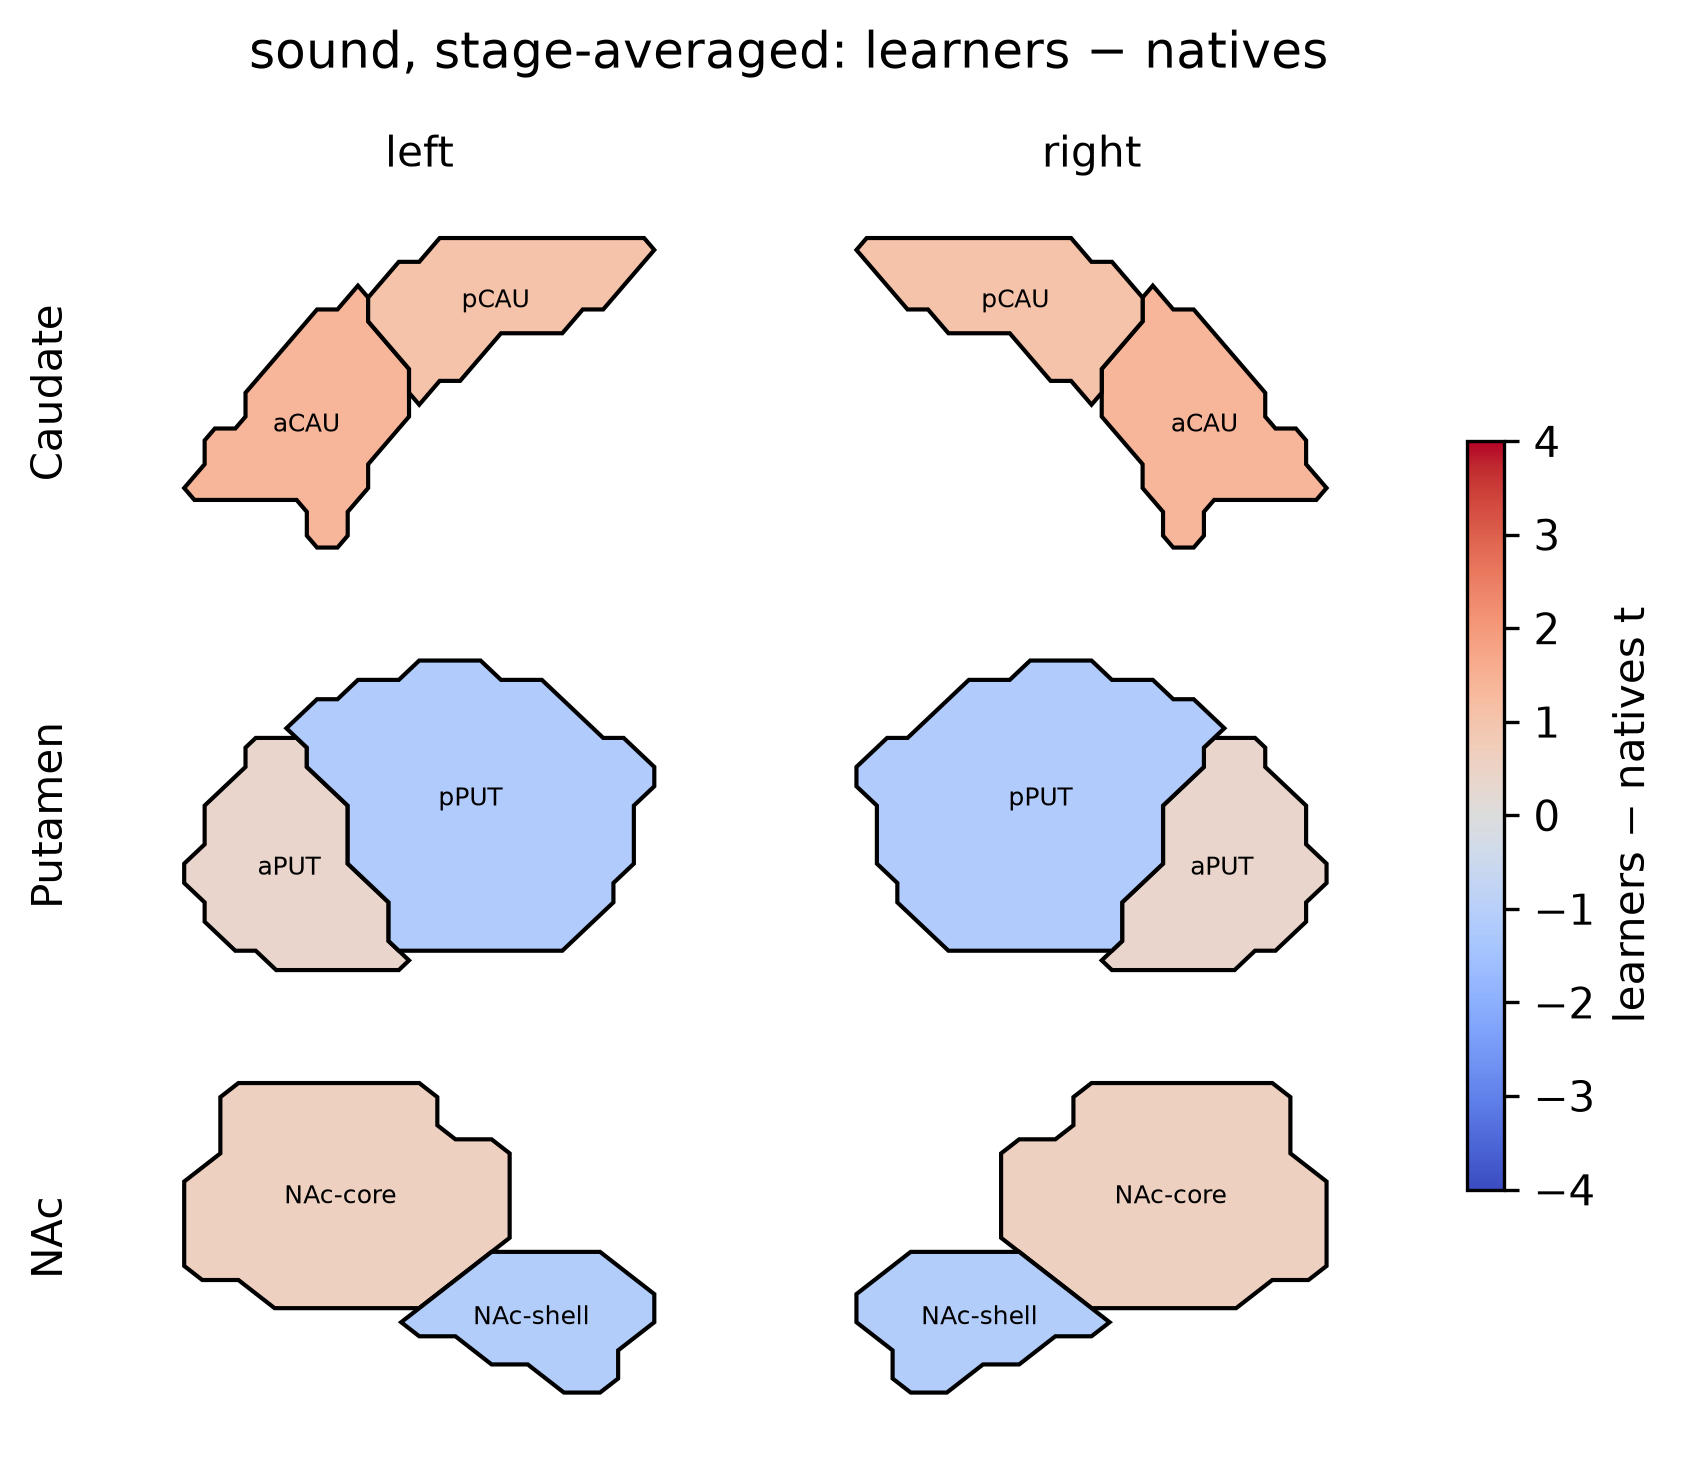

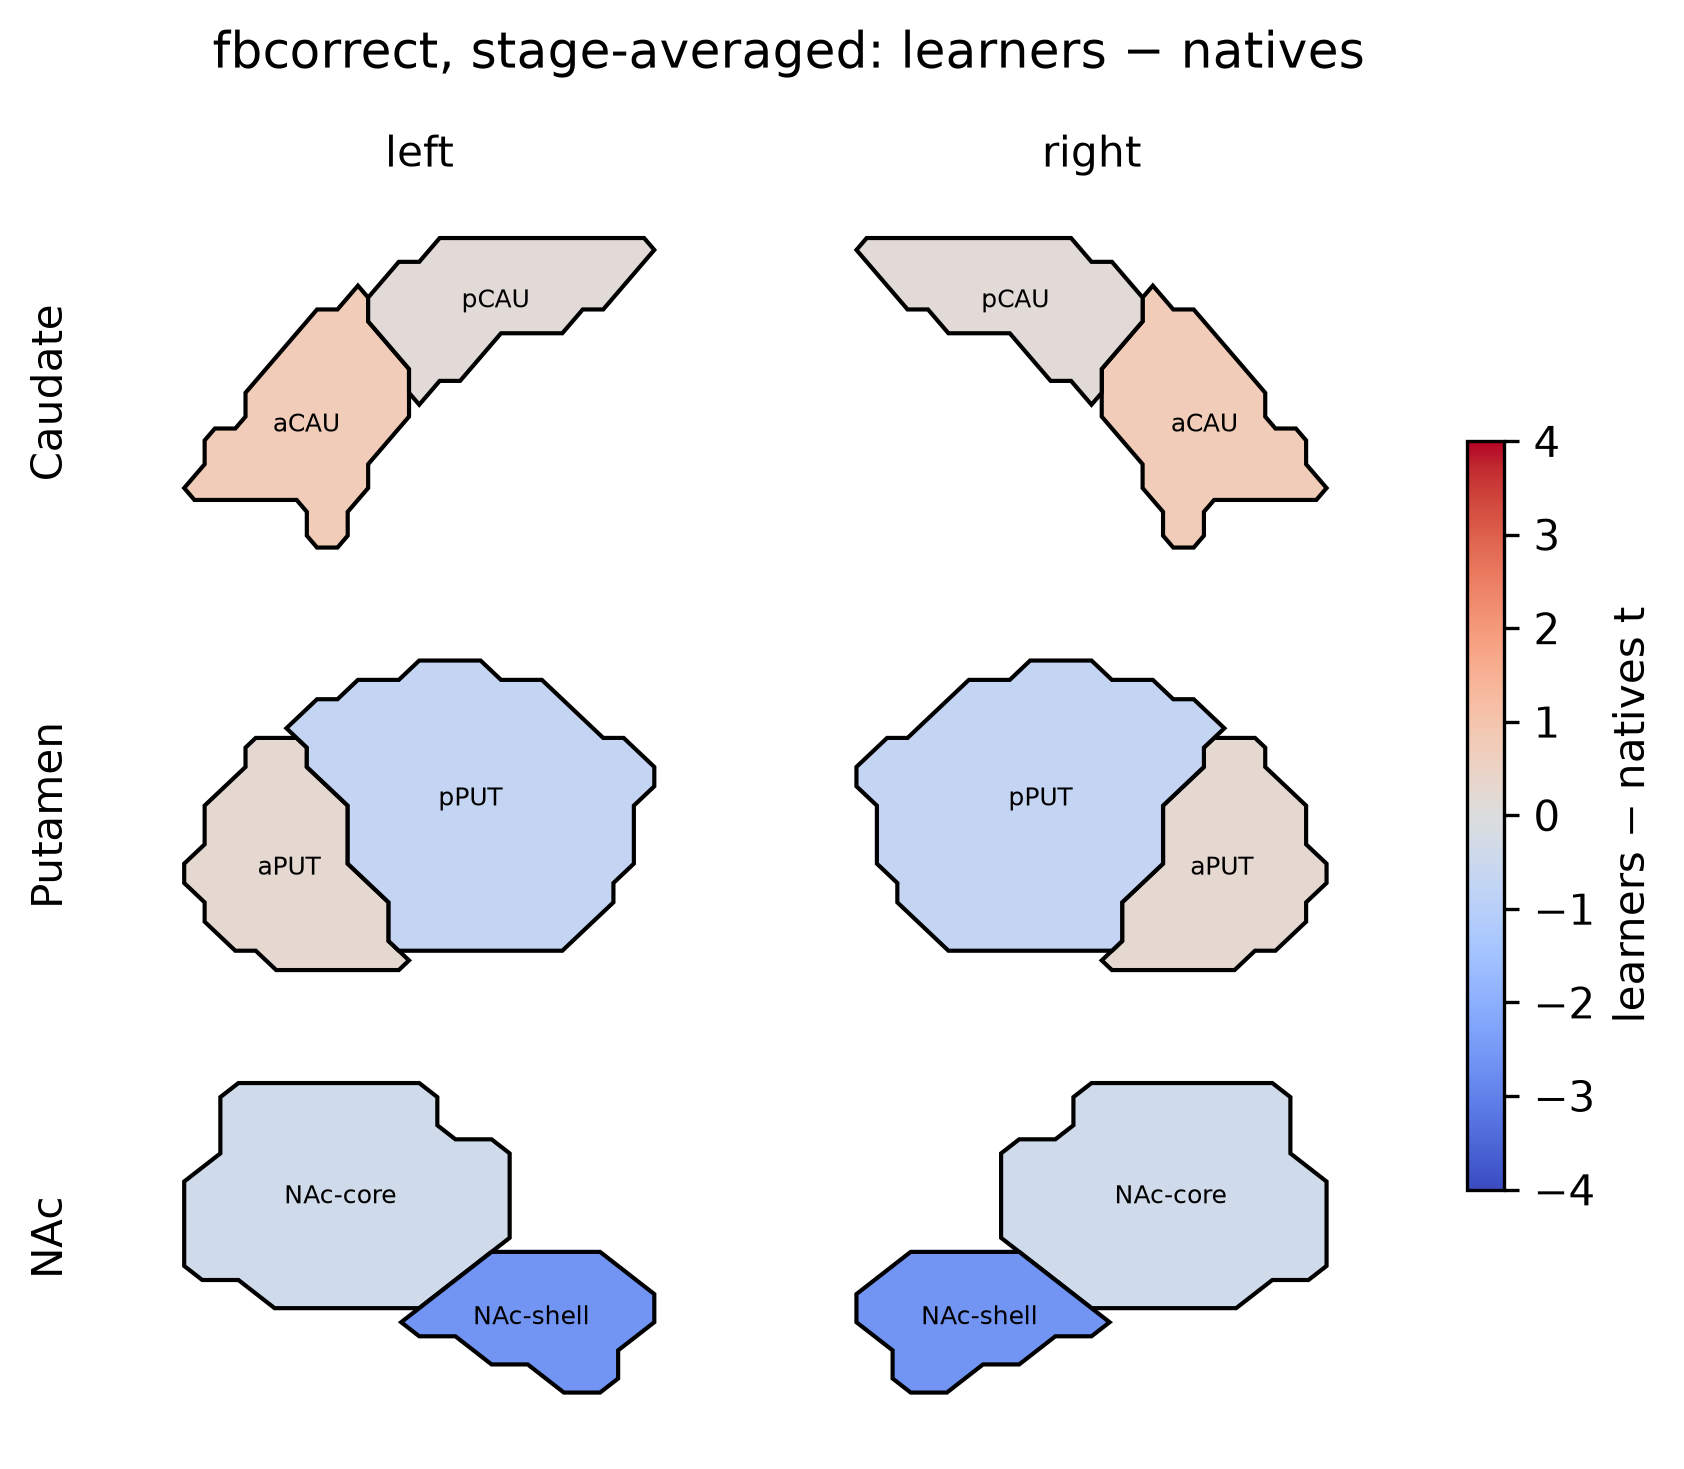

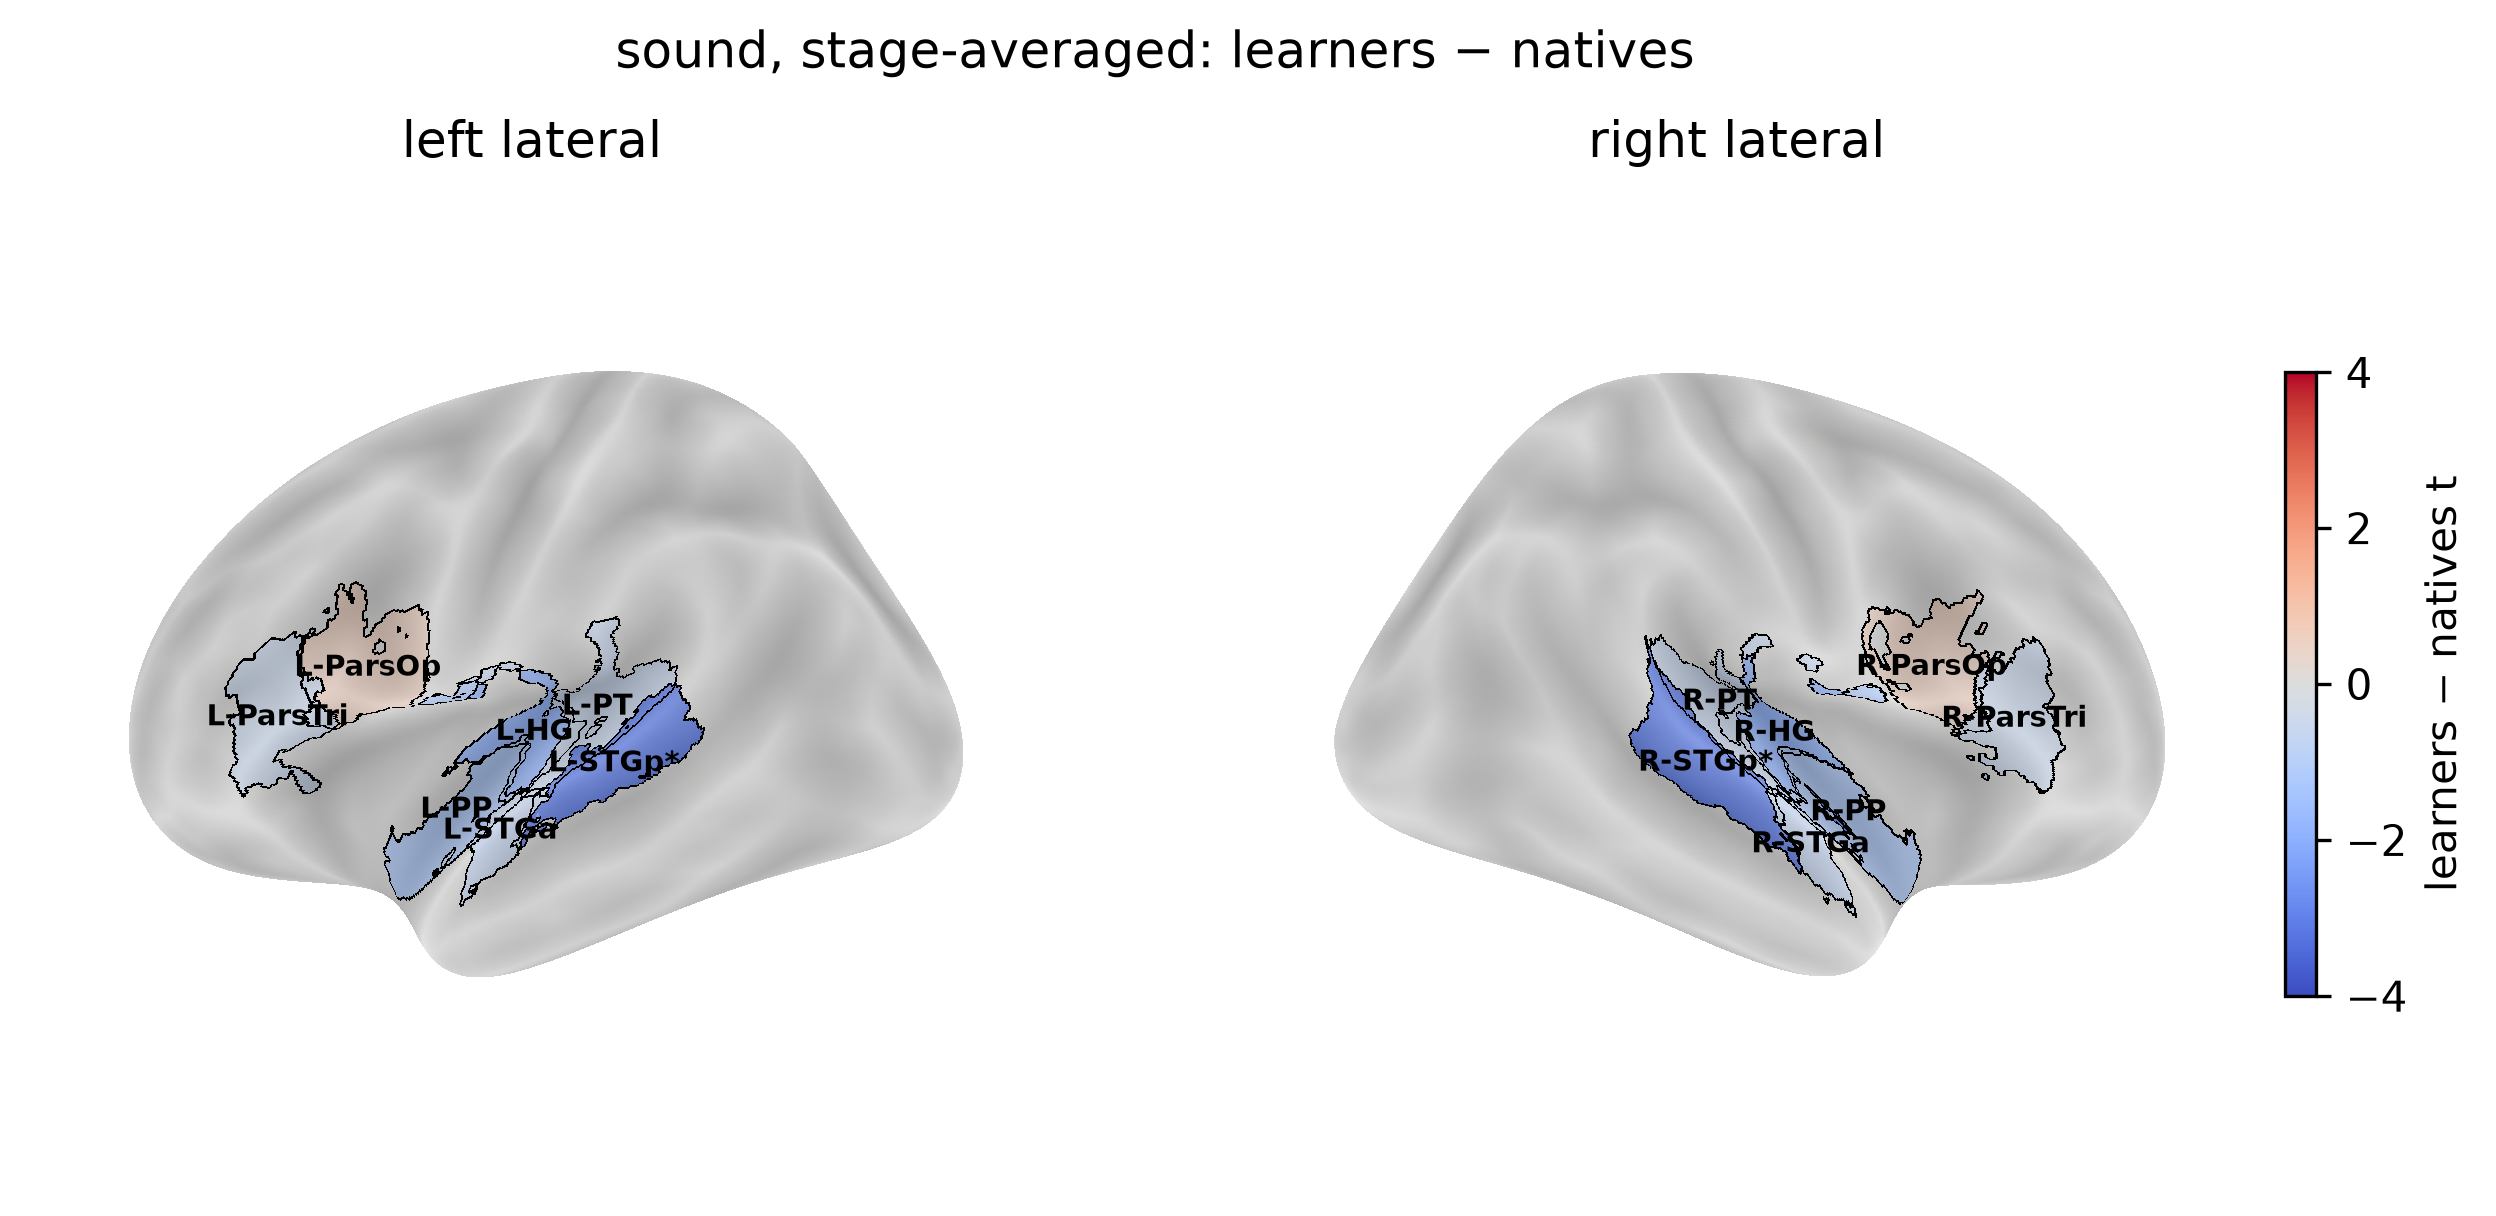

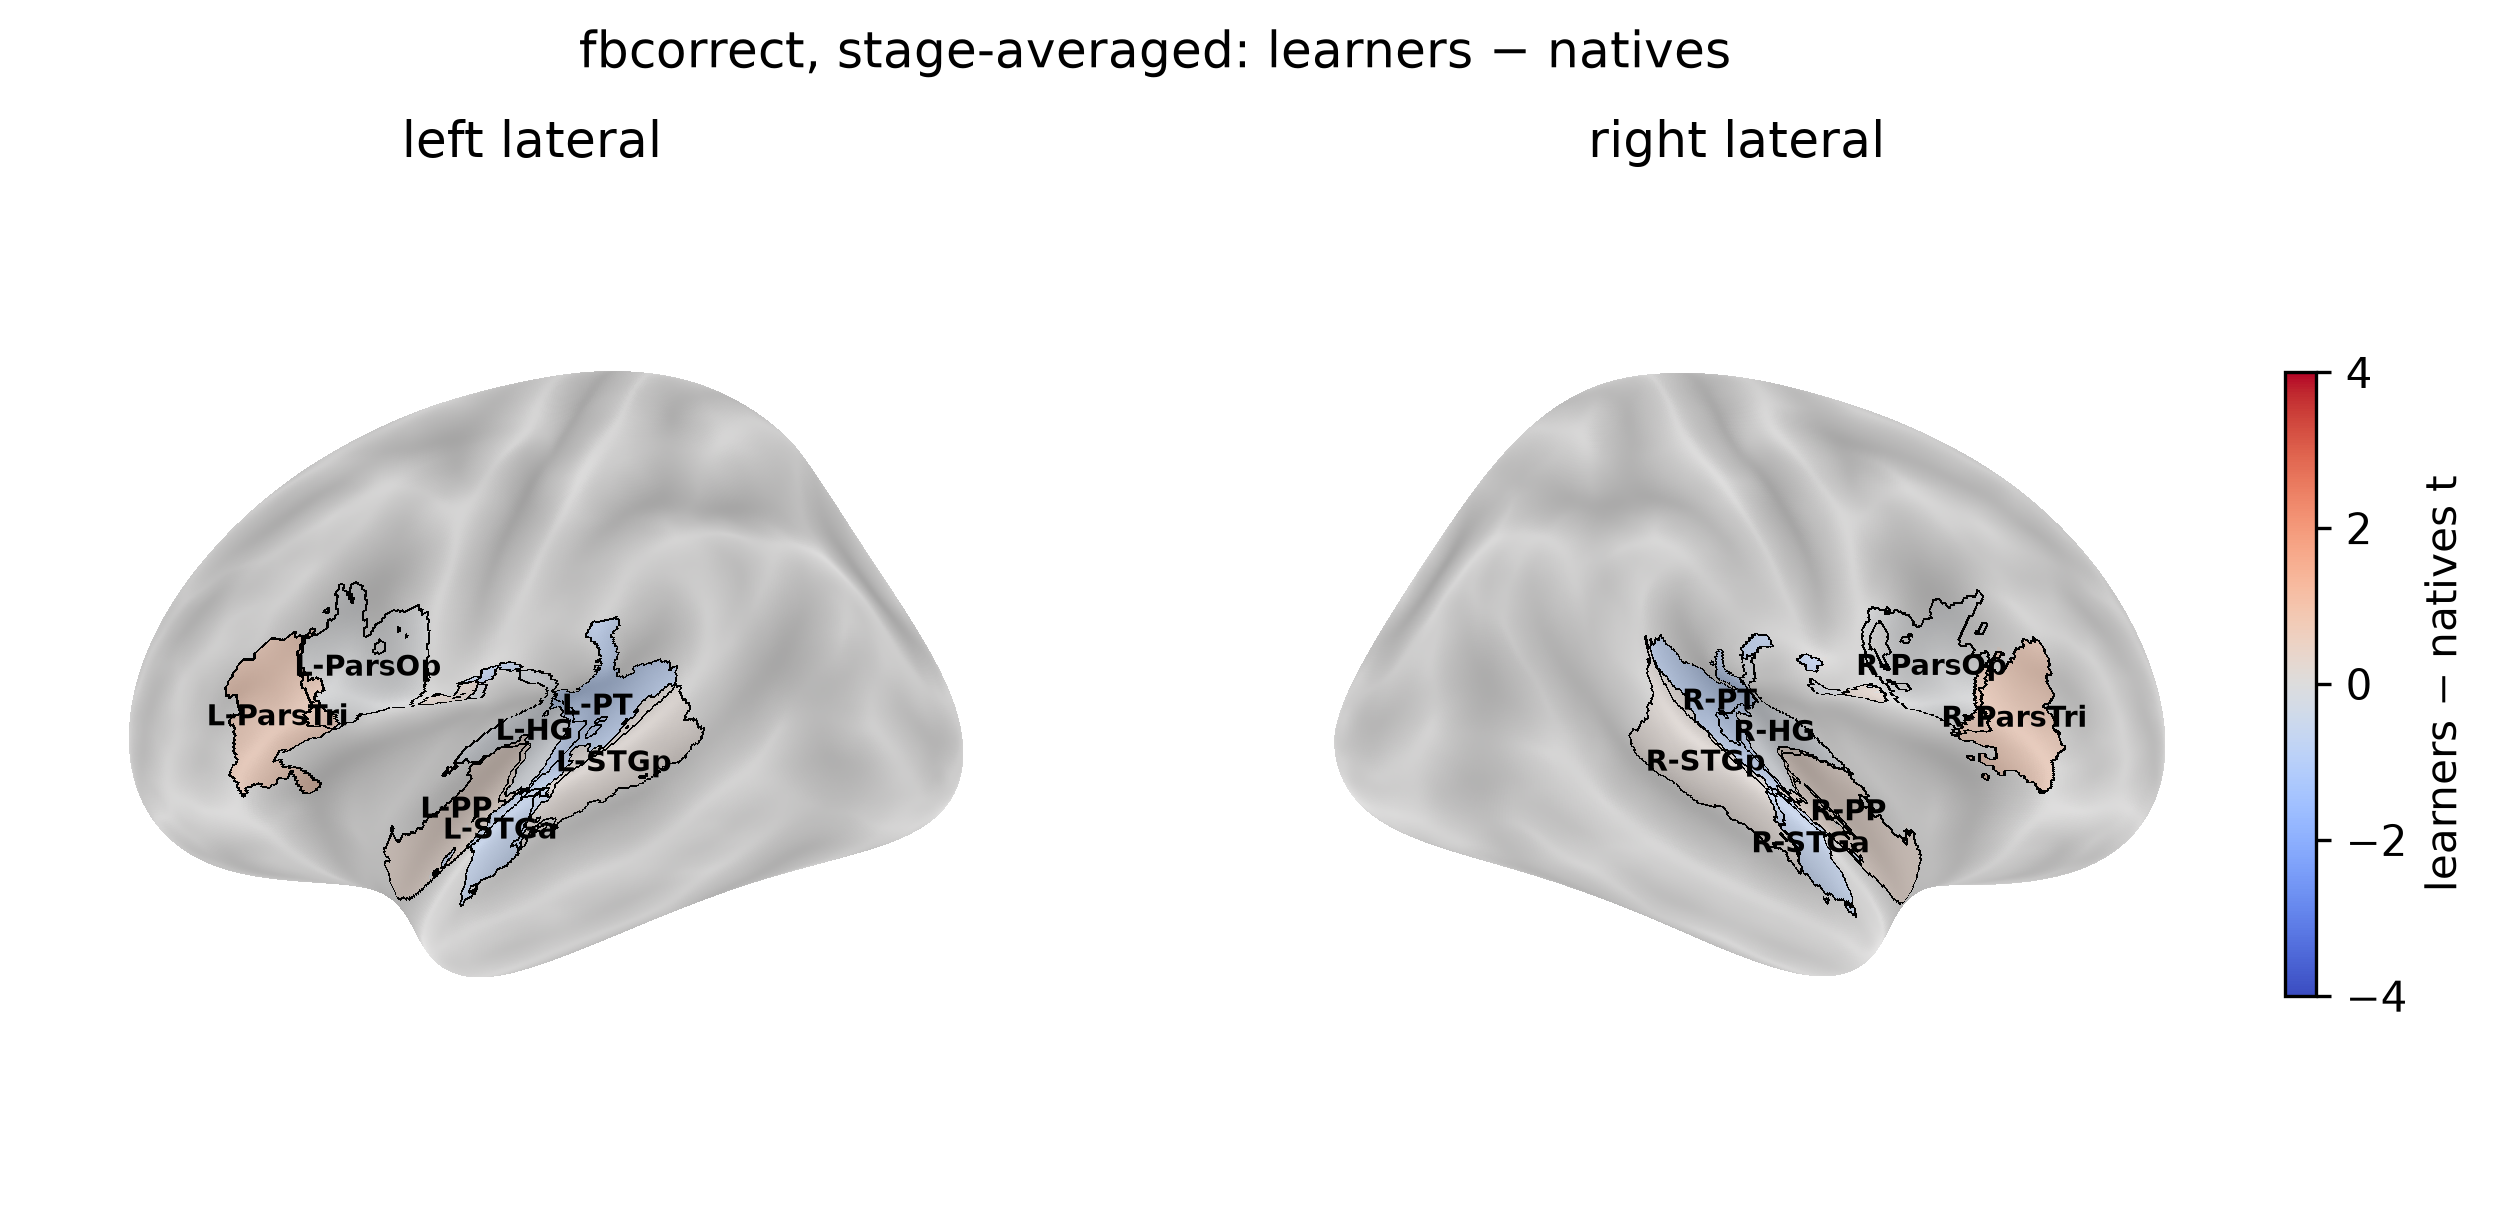

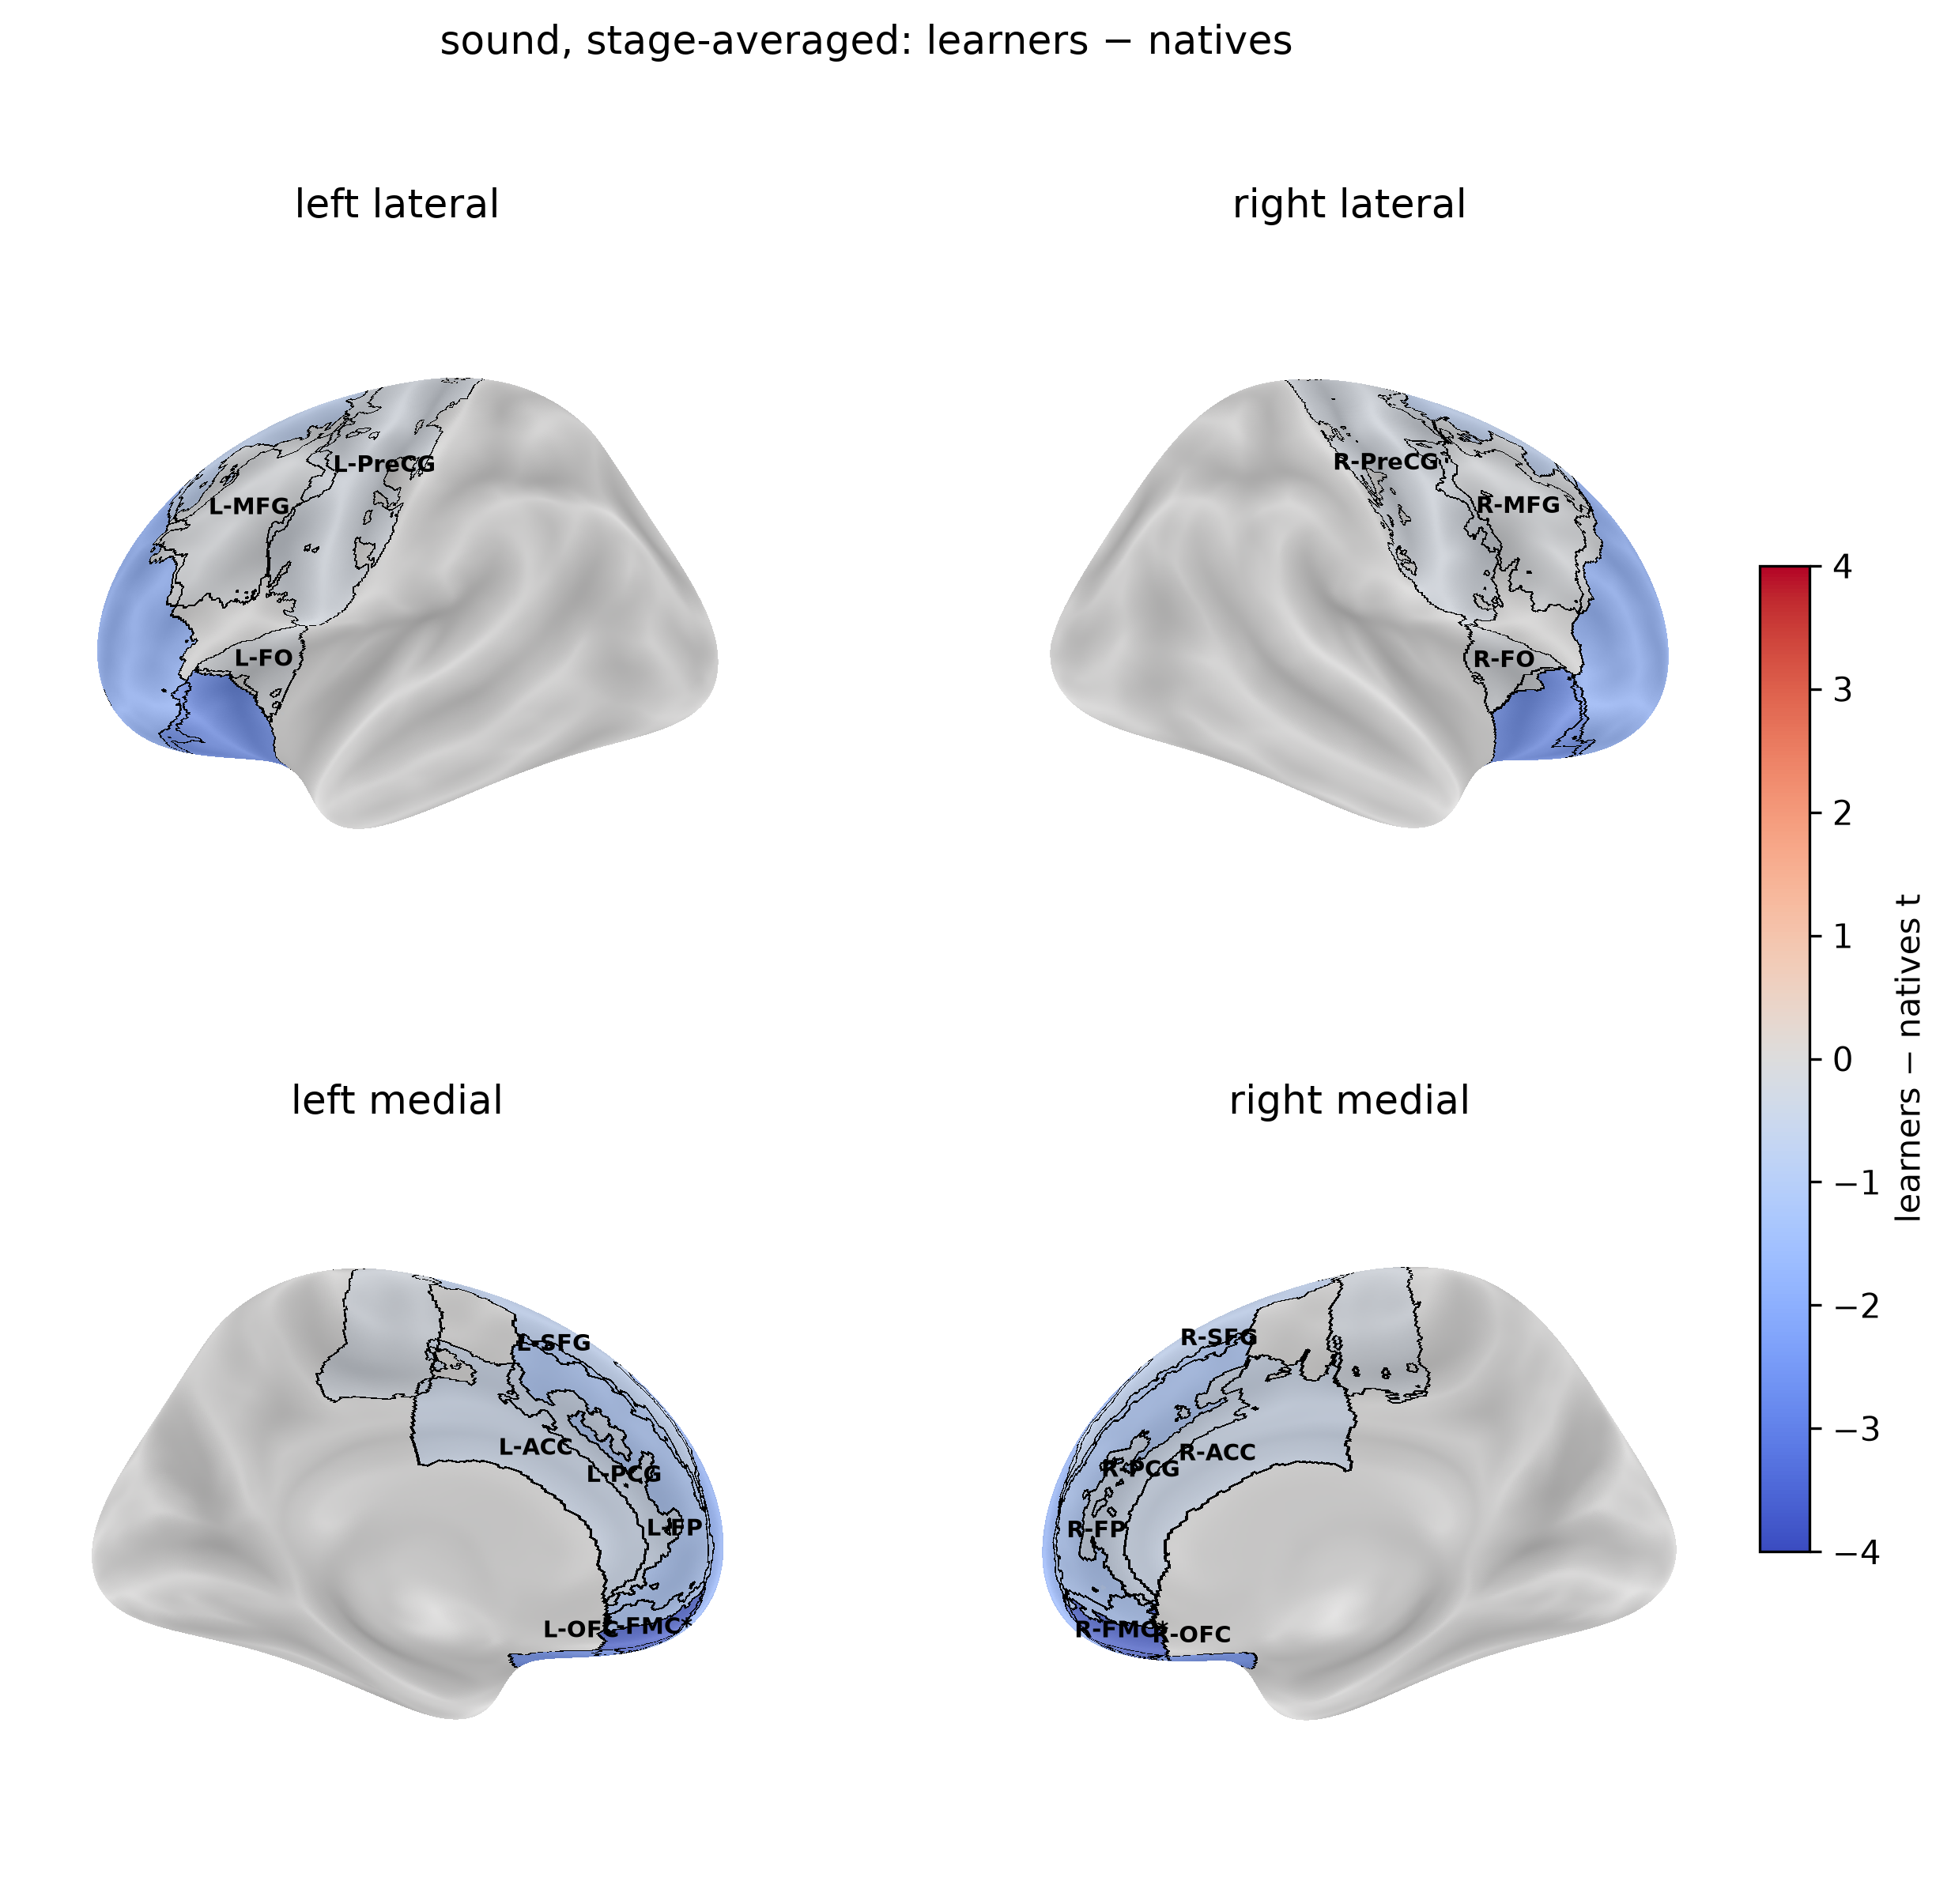

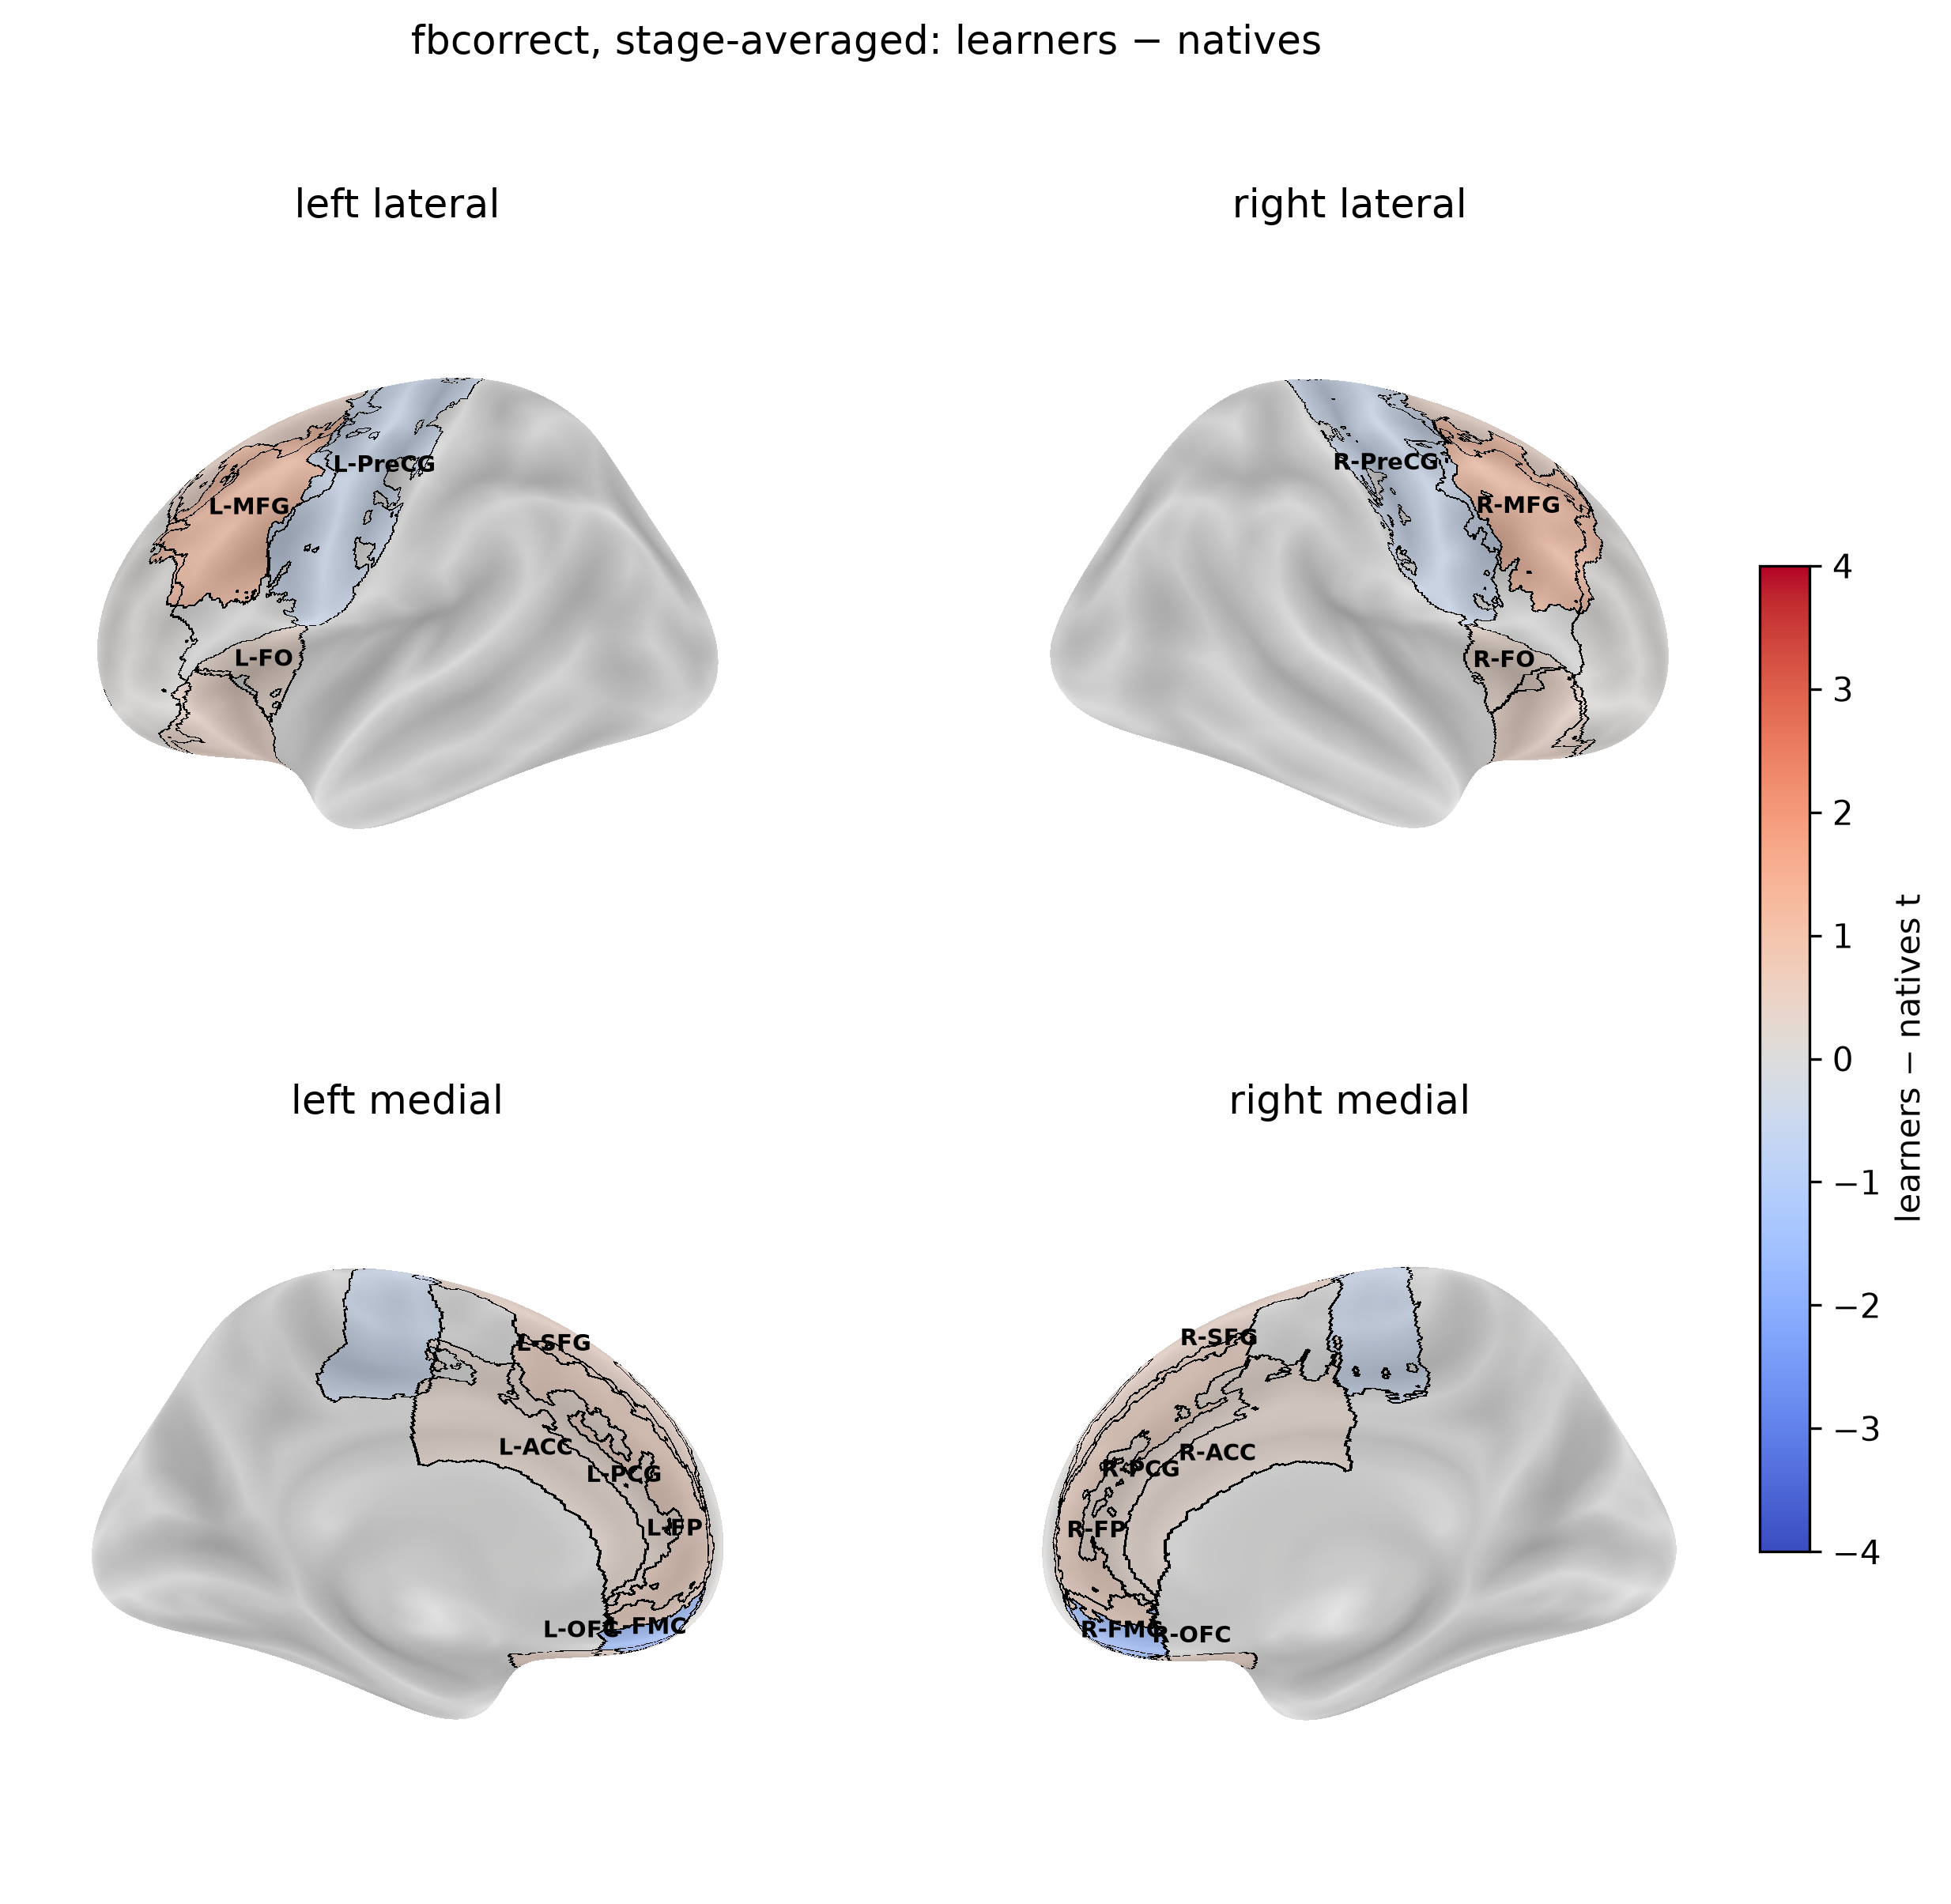

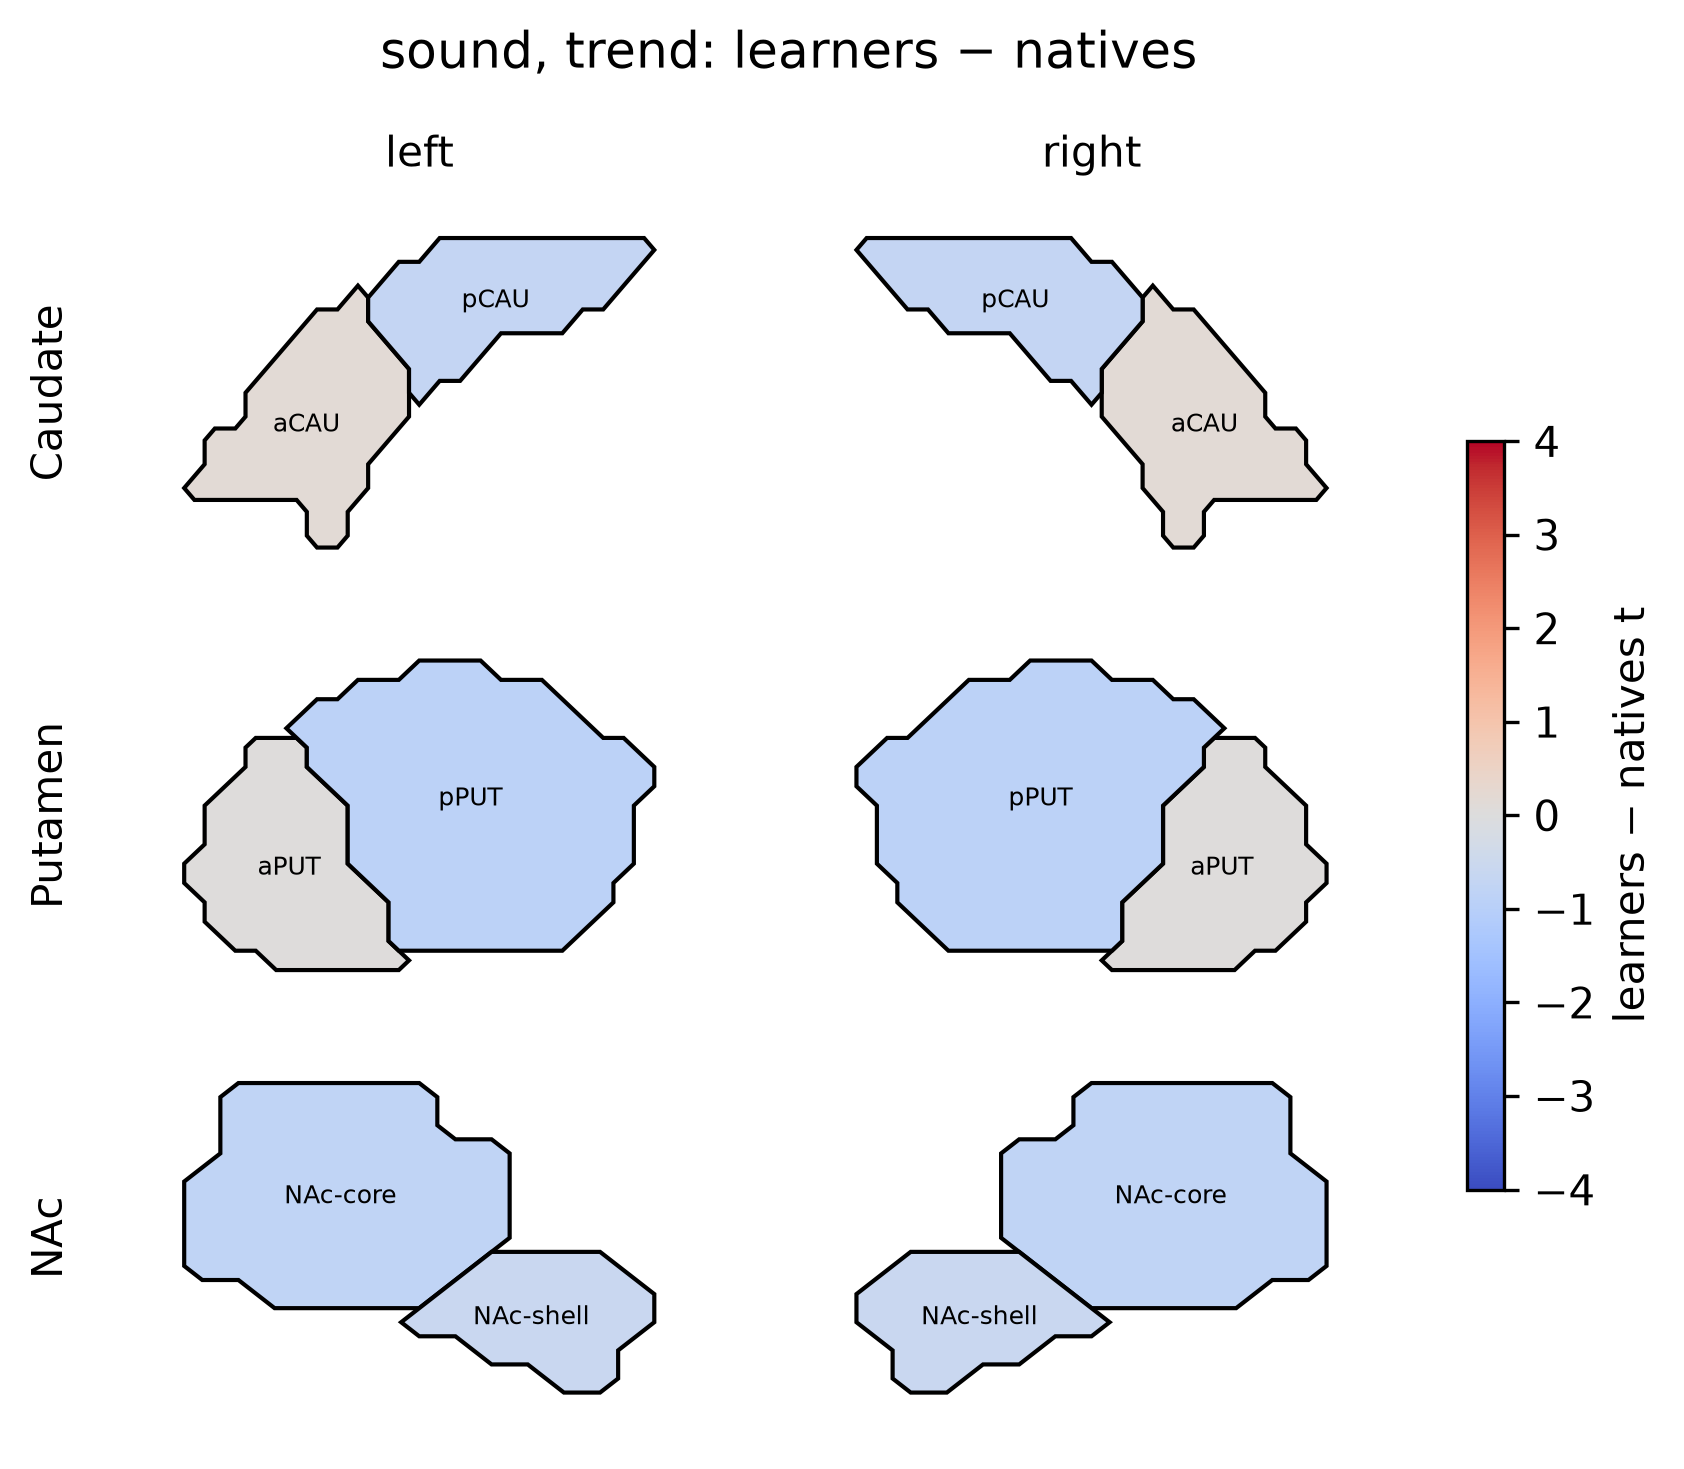

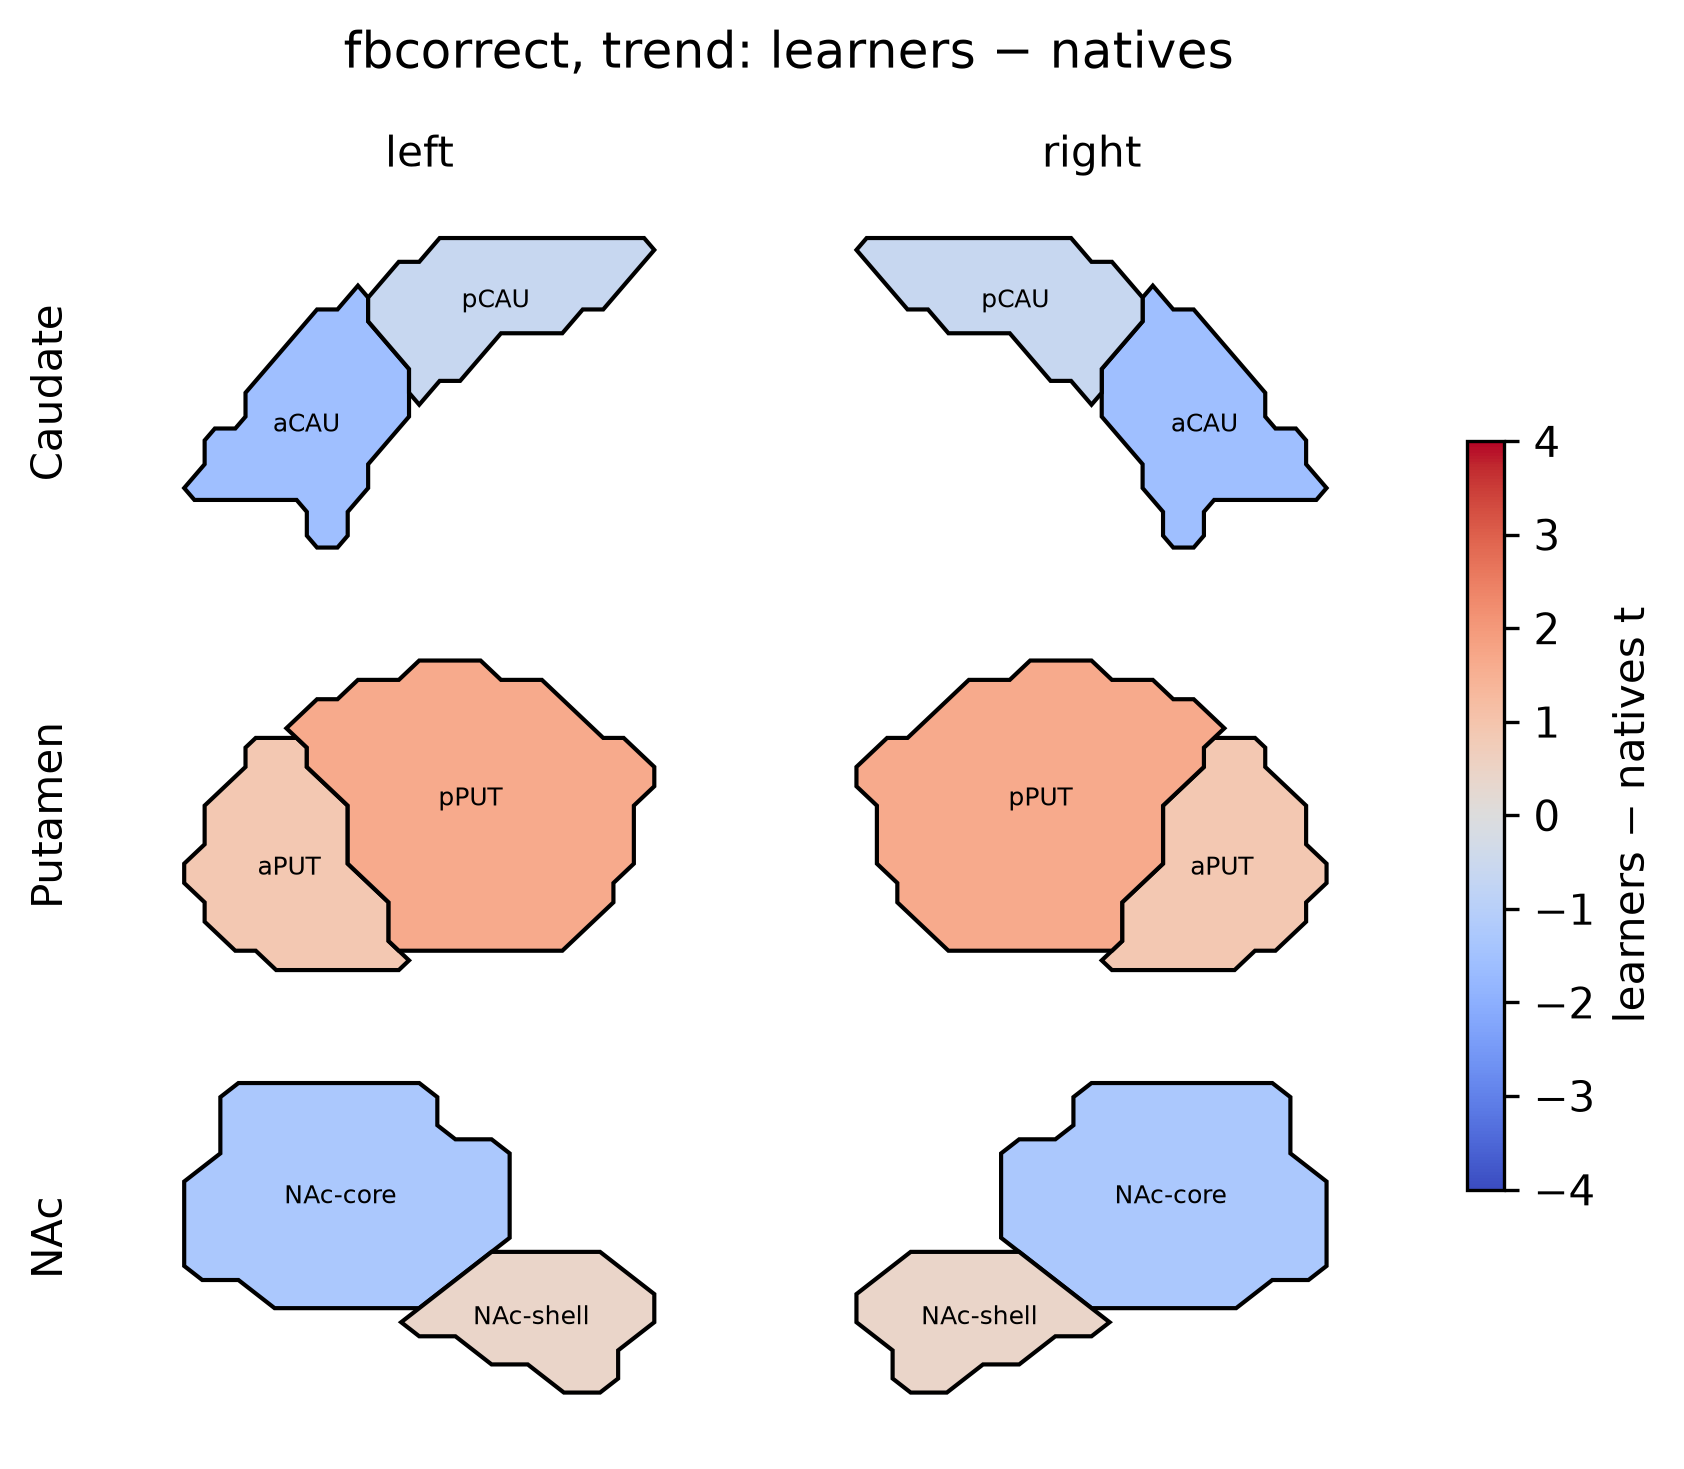

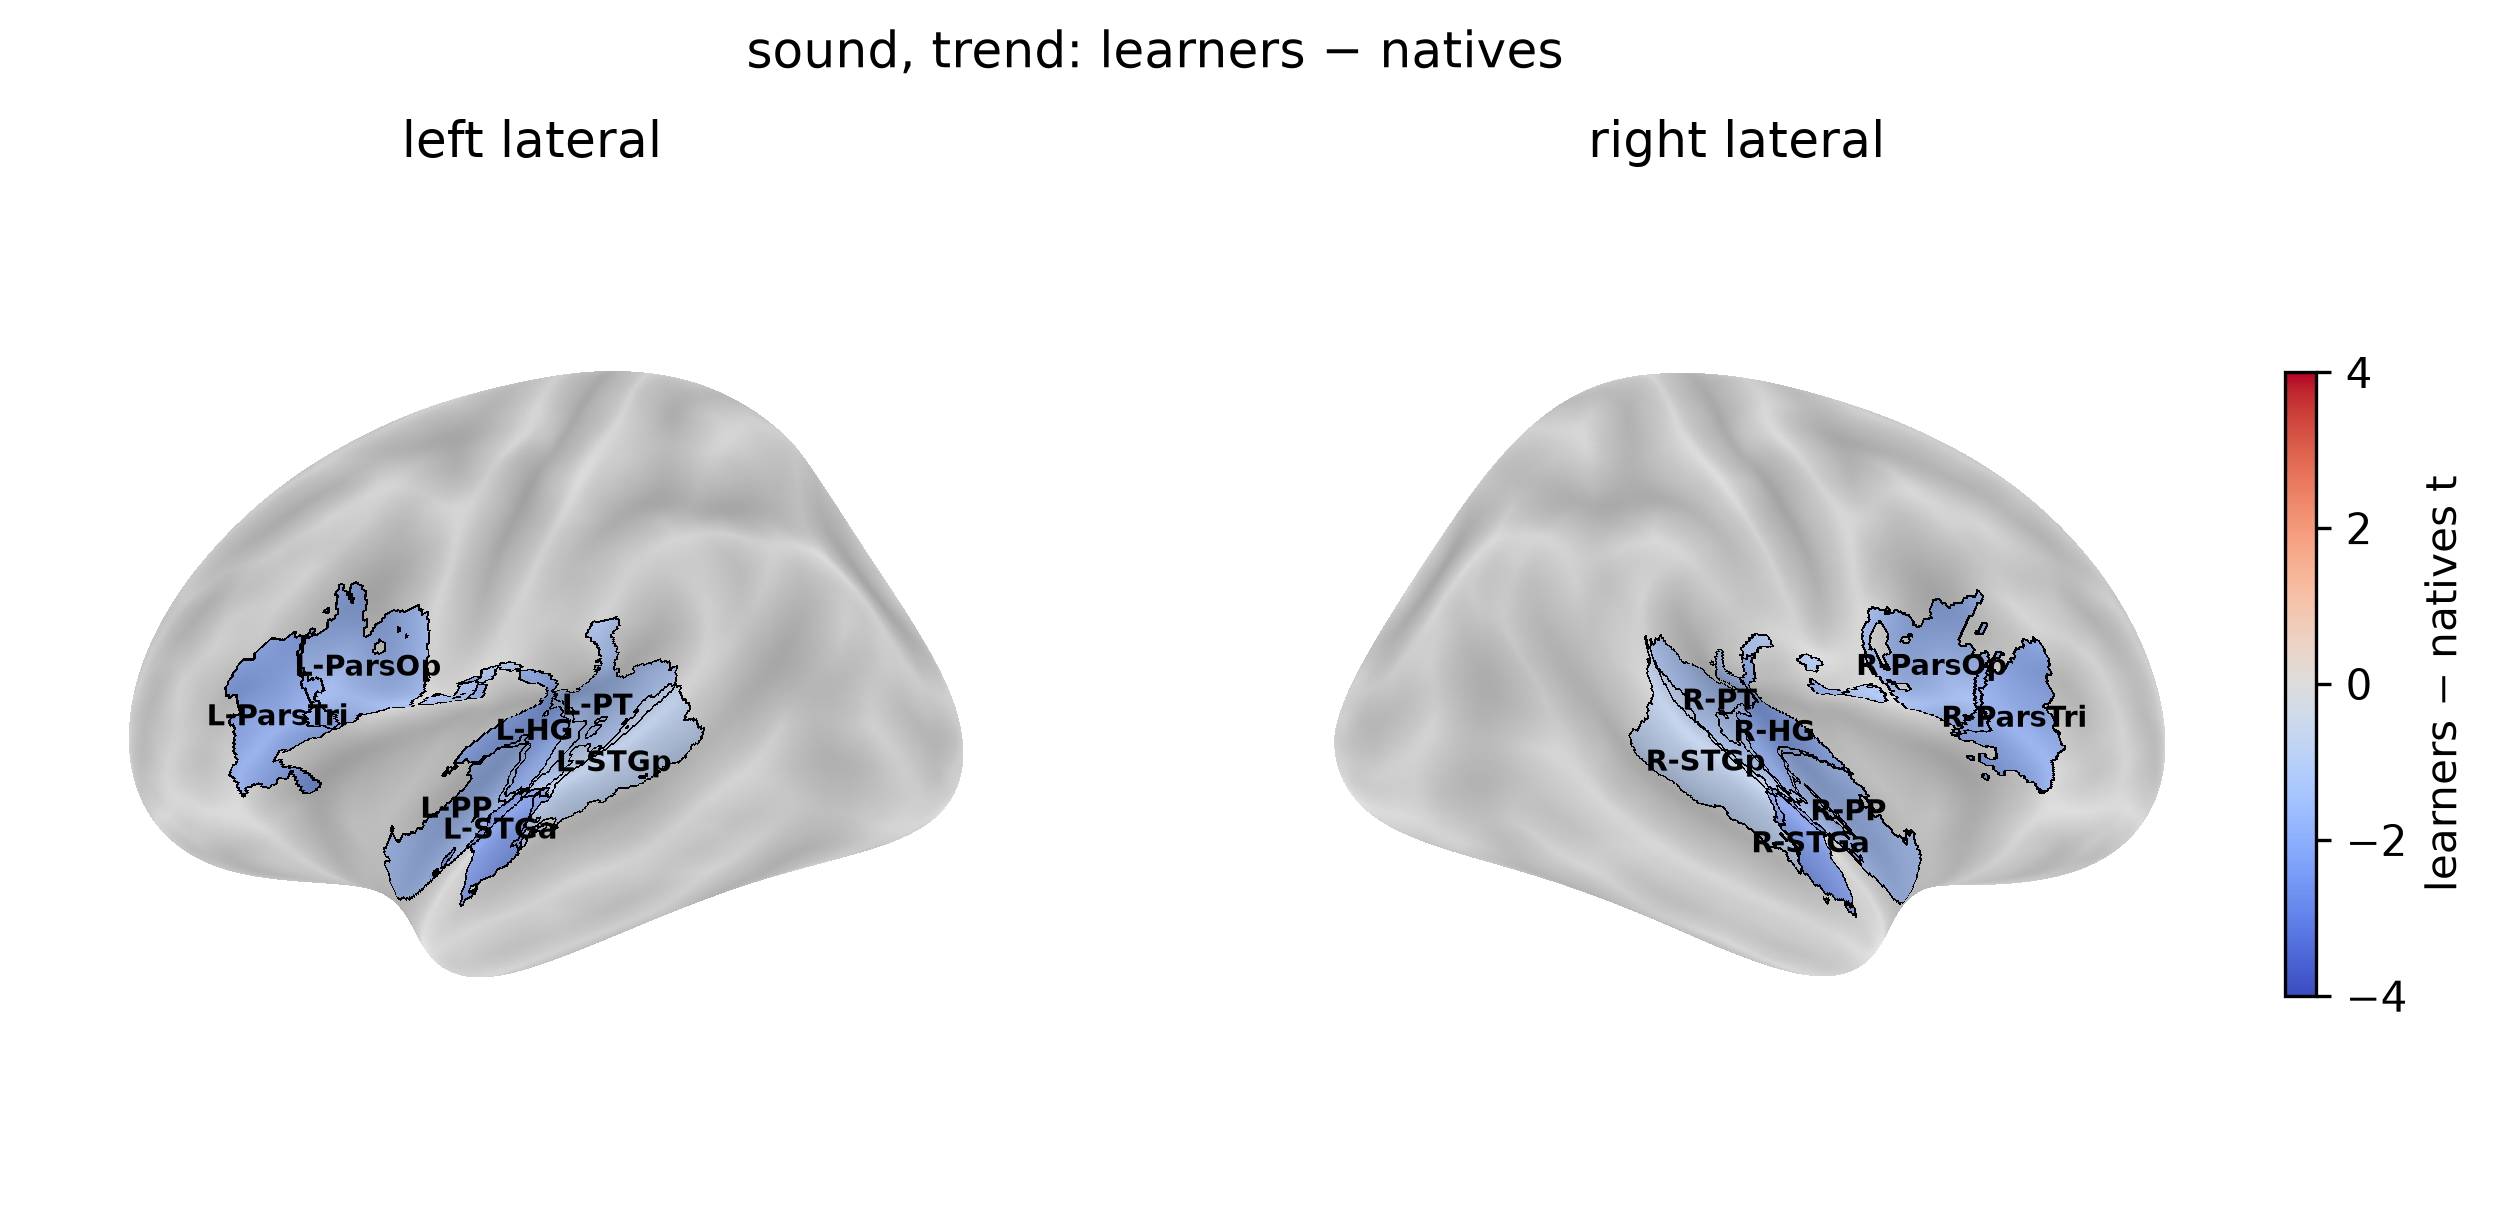

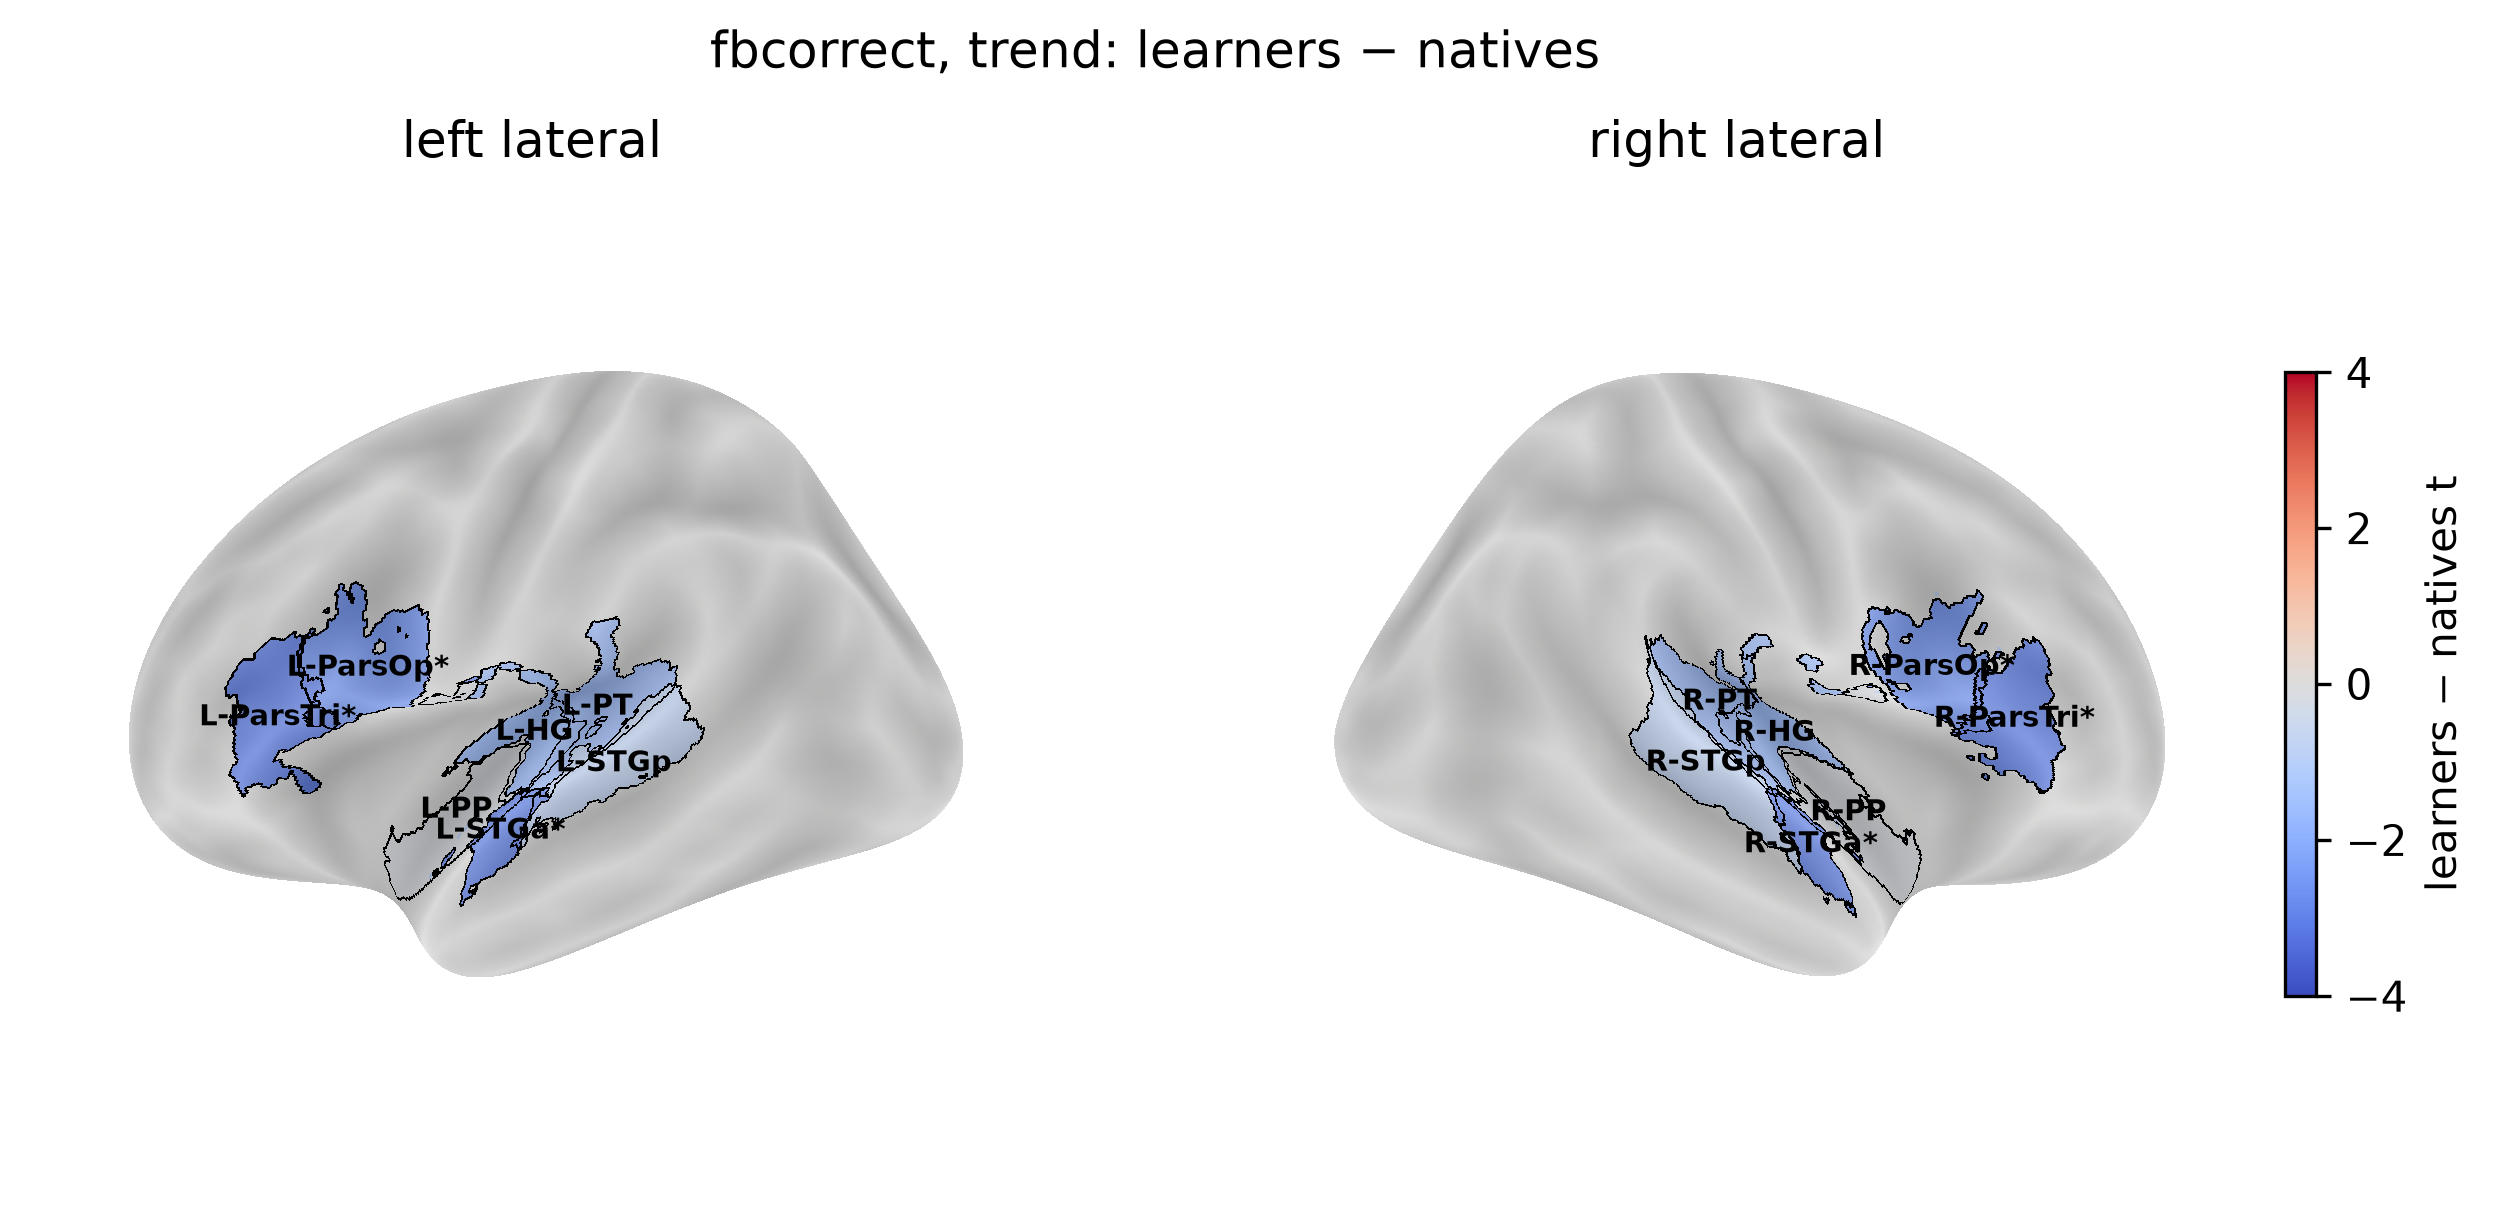

In [ ]:
# 2. ROI maps of learners - natives t (bilateral t on both hemispheres)
VLIM = 4   # one colour scale for every group-difference map
CONTRAST_LABEL = {'sound': 'sound', 'fbcorrect': 'correct feedback'}
STRUCTURE_GROUPS = {'Caudate': ['aCAU', 'pCAU'], 'Putamen': ['aPUT', 'pPUT'], 'NAc': ['NAc-core', 'NAc-shell']}
region_hemis = df[['network', 'region', 'region_hemi']].drop_duplicates()

def plot_group_map(results, network, contrast, measure):
    sub = results[(results.network == network) & (results.contrast == contrast)].set_index('region')
    names = region_hemis[(region_hemis.network == network) & region_hemis.region.isin(sub.index)]
    stat = {rh: sub.loc[r, 't'] for r, rh in zip(names.region, names.region_hemi)}
    significant = [rh for r, rh in zip(names.region, names.region_hemi) if sub.loc[r, 'q'] < .05]
    mask_paths = build_mask_path_dict(list(stat), masks_dir, network, surf_space_label)
    title = f'{CONTRAST_LABEL[contrast]}, {measure}: learners − natives'
    if network == 'tian-S2':
        fig = plot_striatal_roi_stat(stat, mask_paths, STRUCTURE_GROUPS, vlim=VLIM, title=title,
                                     highlight=significant, cbar_label='learners − natives t')
    else:
        fig = plot_roi_surface_stat(stat, mask_paths, fsaverage=fsaverage, vlim=VLIM, title=title,
                                    views=('lateral',) if network == 'auditory' else ('lateral', 'medial'),
                                    highlight=significant, cbar_label='learners − natives t',
                                    hemi_prefix_labels=False)
    save(fig, f'group-diff_network-{network}_contrast-{contrast}_{measure.replace(" ", "-")}',
         exts=('png', 'svg') if network == 'tian-S2' else ('png',))
    return fig

for results, measure in [(group_diff, 'stage-averaged'), (trend_diff, 'trend')]:
    for network in gs.NETWORKS:
        for contrast in ['sound', 'fbcorrect']:
            plot_group_map(results, network, contrast, measure)
            plt.show()

In [ ]:
# 3. the three key results, one point per participant
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}
group_names = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}
means = gs.subject_means(df)
acau_minus_aput = gs.differential_trend(trends, 'fbcorrect', 'aCAU', 'aPUT')
key_panels = [
    (means.query("contrast == 'sound' and region == 'FMC'"), 'beta', 'FMC, sound', 'stage-averaged β',
     group_diff.query("contrast == 'sound' and region == 'FMC'").iloc[0]),
    (means.query("contrast == 'sound' and region == 'STGp'"), 'beta', 'STGp, sound', 'stage-averaged β',
     group_diff.query("contrast == 'sound' and region == 'STGp'").iloc[0]),
    (acau_minus_aput, 'trend', 'aCAU − aPUT, correct feedback', 'trend (final − early)',
     planned.query("region == 'aCAU-minus-aPUT'").iloc[-1]),
]
rng_jitter = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(key_panels), figsize=(3.0 * len(key_panels), 3.4))
for ax, (data, value, title, ylabel, stat) in zip(axes, key_panels):
    for x, g in enumerate(gs.GROUPS):
        v = data.loc[data.participant_group == g, value].values
        ax.scatter(x + rng_jitter.uniform(-.12, .12, len(v)), v, s=22, color=colors[g], alpha=.75,
                   edgecolor='white', linewidth=.5, zorder=2)
        ci = stats.t.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
        ax.errorbar(x + .3, v.mean(), yerr=ci, fmt='o', ms=7, color='0.15', capsize=0, lw=1.5, zorder=3)
    ax.axhline(0, color='0.6', lw=0.8, ls='--', zorder=0)
    ax.set_xticks([0, 1], [group_names[g] for g in gs.GROUPS])
    ax.set_xlim(-.5, 1.6)
    ax.set_ylabel(ylabel, fontsize=8)
    # planned test (section 4) reports p and its bootstrap CI; 5b rows report d and q
    note = (f"d = {stat.d:.2f}, q = {stat.q:.3f}" if 'q' in stat.index
            else f"diff = {stat.estimate:.2f}, p = {stat.p:.3f}")
    ax.set_title(f'{title}\n{note}', fontsize=9)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
fig.tight_layout()
save(fig, 'group-diff_key-results')

## 7. Learners only: headline `fbcorrectvswrong`

For reference alongside section 4; values match `robustness_summary.csv`.

In [ ]:
learners = trends[trends.participant_group == 'non-Mandarin']
rows = []
for label, values in [('aCAU', learners.query("contrast == 'fbcorrectvswrong' and region == 'aCAU'").trend),
                      ('aCAU-minus-aPUT', gs.differential_trend(trends, 'fbcorrectvswrong', 'aCAU', 'aPUT')
                                            .query("participant_group == 'non-Mandarin'").trend)]:
    loso = gs.leave_one_out_stability(values)
    rows.append({'trend': label, 'n': len(values), 'mean': values.mean(),
                 't': loso['original_t'], 'p': loso['original_p'],
                 'exact_permutation_p': gs.exact_sign_flip_permutation_test(values)['p_value'],
                 'loso_preserved': f"{loso['n_preserved']}/{loso['n_folds']}"})
pd.DataFrame(rows).round(4)